In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
PROJECT_DIR = Path.cwd()

print("Project directory:", PROJECT_DIR)

csv_files = list(PROJECT_DIR.rglob("*.csv"))

print("\nAvailable CSV datasets:")

for file in csv_files:
    print(file)

Project directory: C:\Users\DELL

Available CSV datasets:
C:\Users\DELL\cleaning_log.csv
C:\Users\DELL\dataset_metadata.csv
C:\Users\DELL\hour.csv
C:\Users\DELL\India_Flood_Inventory_v3.csv
C:\Users\DELL\labels.csv
C:\Users\DELL\predictions_concrete.csv
C:\Users\DELL\segments.csv
C:\Users\DELL\segment_profile.csv
C:\Users\DELL\.ipynb_checkpoints\dataset_metadata-checkpoint.csv
C:\Users\DELL\.ipynb_checkpoints\India_Flood_Inventory_v3-checkpoint.csv
C:\Users\DELL\data\hour.csv
C:\Users\DELL\data\hyderabad_historical_flood_events.csv
C:\Users\DELL\data\hyderabad_rainfall.csv
C:\Users\DELL\data\hyderabad_rainfall_2020_09_25.csv
C:\Users\DELL\Downloads\hour.csv
C:\Users\DELL\Downloads\hyderabad_historical_flood_events.csv
C:\Users\DELL\Downloads\hyderabad_rainfall.csv
C:\Users\DELL\Downloads\hyderabad_rainfall_2020_09_25.csv
C:\Users\DELL\Downloads\India_Flood_Inventory_v3.csv
C:\Users\DELL\Downloads\Urban_Heat_Metrics_Tmax_90p_3-5days.csv
C:\Users\DELL\flood_analysis_results\daily_rainfal

In [4]:
rainfall_matches = list(PROJECT_DIR.rglob("hyderabad_rainfall.csv"))

if not rainfall_matches:
    print("Dataset not found. Available CSV files:")
    for file in csv_files:
        print(file)
else:
    rainfall_file = rainfall_matches[0]
    rainfall = pd.read_csv(rainfall_file)

    print("Dataset loaded successfully!")
    print("File:", rainfall_file)
    print("Shape:", rainfall.shape)

    display(rainfall.head())

Dataset loaded successfully!
File: C:\Users\DELL\data\hyderabad_rainfall.csv
Shape: (84, 4)


,date,latitude,longitude,rainfall_mm
0,2020-09-25,17.525,78.325,21.588670
1,2020-09-25,17.525,78.375,20.557886
2,2020-09-25,17.525,78.425,16.716734
3,2020-09-25,17.525,78.475,15.319092
4,2020-09-25,17.525,78.525,16.243406


In [5]:
print("Dataset information:")
rainfall.info()

print("\nColumn names:")
print(rainfall.columns.tolist())

print("\nMissing values:")
display(rainfall.isnull().sum())

print("\nStatistical summary:")
display(rainfall.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         84 non-null     str    
 1   latitude     84 non-null     float64
 2   longitude    84 non-null     float64
 3   rainfall_mm  84 non-null     float64
dtypes: float64(3), str(1)
memory usage: 3.6 KB

Column names:
['date', 'latitude', 'longitude', 'rainfall_mm']

Missing values:


date           0
latitude       0
longitude      0
rainfall_mm    0
dtype: int64


Statistical summary:


,latitude,longitude,rainfall_mm
count,84.000000,84.000000,84.000000
mean,17.400000,78.475000,15.283191
std,0.085904,0.100601,3.723850
min,17.275000,78.325000,6.110783
25%,17.325000,78.375000,13.146634
50%,17.400000,78.475000,15.825913
75%,17.475000,78.575000,17.373213
max,17.525000,78.625000,22.855469


In [6]:
# Create a copy so the original dataset remains unchanged
df = rainfall.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Display missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing numerical values with their median
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

Missing values before cleaning:
date           0
latitude       0
longitude      0
rainfall_mm    0
dtype: int64

Missing values after cleaning:
date           0
latitude       0
longitude      0
rainfall_mm    0
dtype: int64

Cleaned dataset shape: (84, 4)


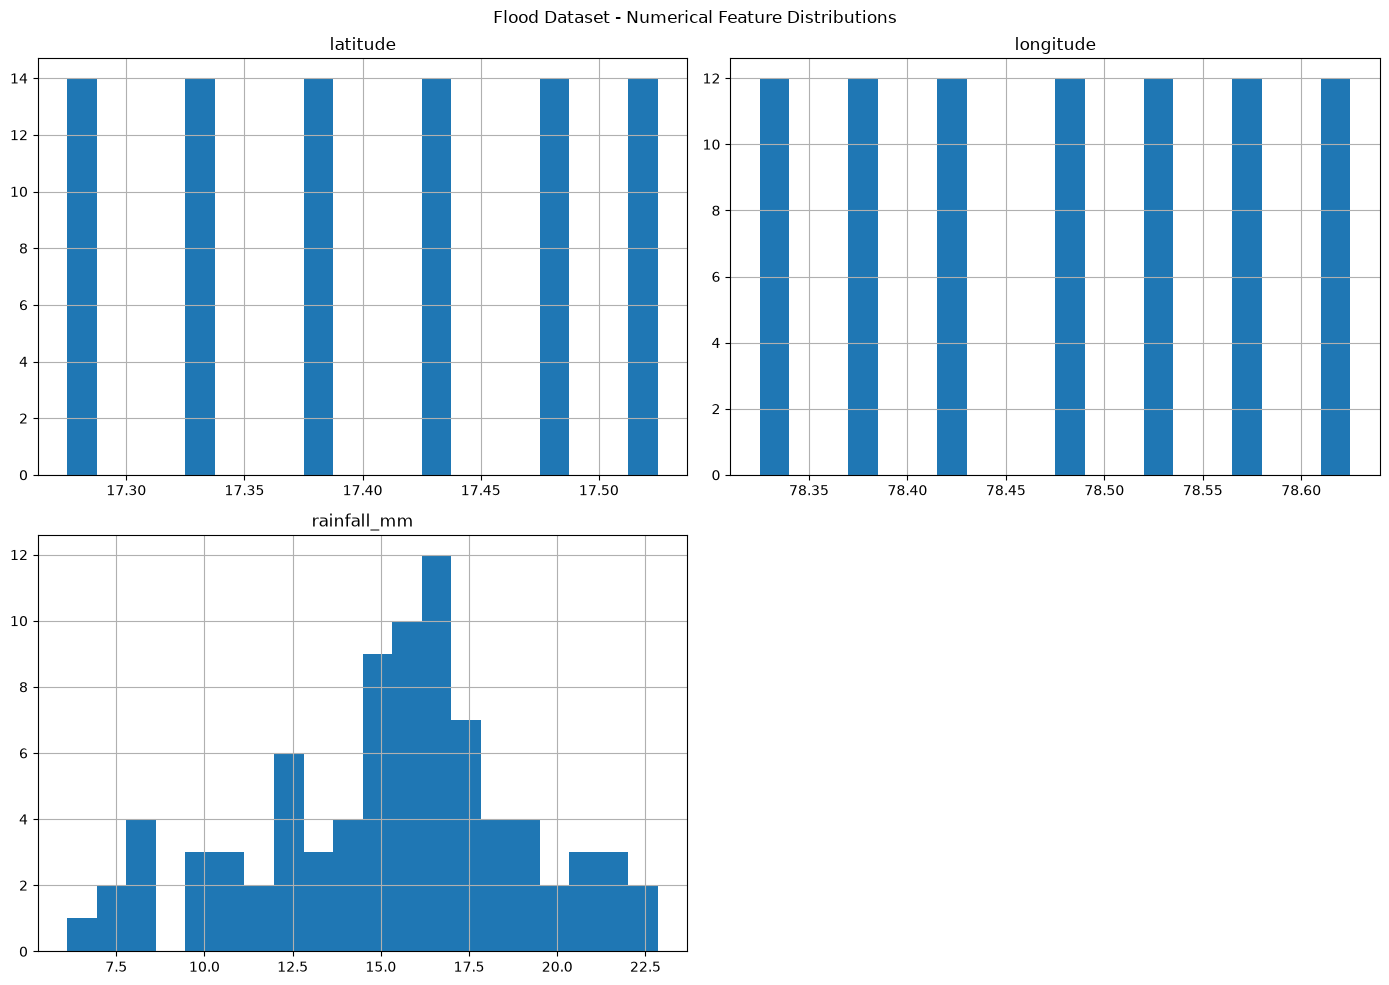

In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Flood Dataset - Numerical Feature Distributions")
plt.tight_layout()
plt.show()

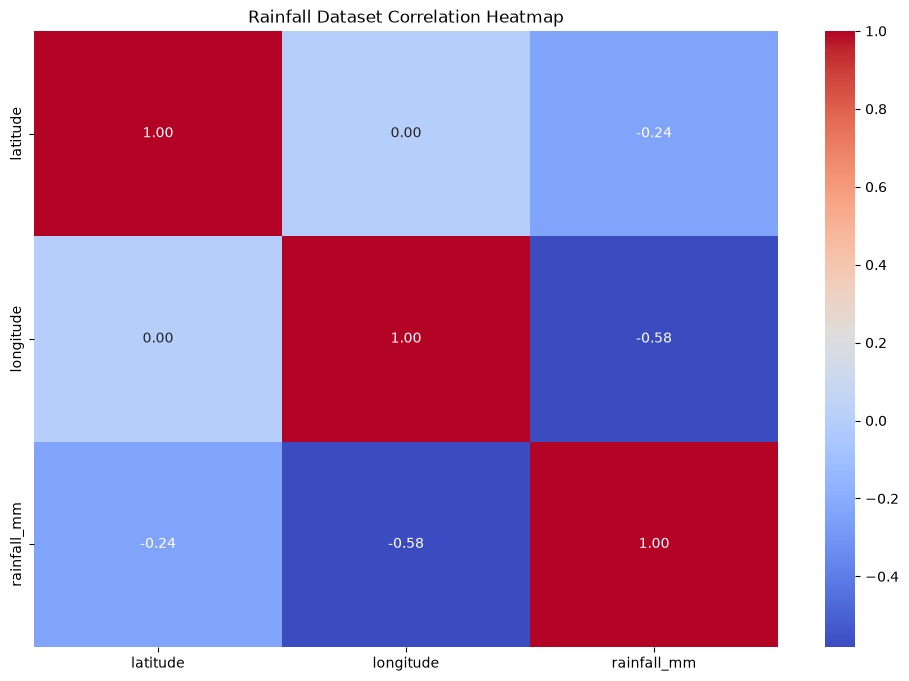

In [8]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Rainfall Dataset Correlation Heatmap")
plt.show()

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

PROJECT_DIR = Path.cwd()

# Find datasets automatically
rainfall_path = next(
    PROJECT_DIR.rglob("hyderabad_rainfall.csv")
)

single_day_path = next(
    PROJECT_DIR.rglob("hyderabad_rainfall_2020_09_25.csv")
)

flood_path = next(
    PROJECT_DIR.rglob("hyderabad_historical_flood_events.csv")
)

# Load datasets
rainfall = pd.read_csv(rainfall_path)
single_day = pd.read_csv(single_day_path)
flood_events = pd.read_csv(flood_path)

print("All three datasets loaded successfully!")

print("Rainfall:", rainfall.shape)
print("Single-day rainfall:", single_day.shape)
print("Historical flood events:", flood_events.shape)

display(rainfall.head())
display(flood_events.head())

All three datasets loaded successfully!
Rainfall: (84, 4)
Single-day rainfall: (42, 3)
Historical flood events: (40, 11)


,date,latitude,longitude,rainfall_mm
0,2020-09-25,17.525,78.325,21.588670
1,2020-09-25,17.525,78.375,20.557886
2,2020-09-25,17.525,78.425,16.716734
3,2020-09-25,17.525,78.475,15.319092
4,2020-09-25,17.525,78.525,16.243406


,UEI,Start Date,End Date,Start_Date_Parsed,End_Date_Parsed,Main Cause,Districts,State,Duration(Days),Human fatality,Human injured
0,UEI-IMD-FL-1969-0008,15-09-1969 00:00,22-09-1969 00:00,1969-09-15,1969-09-22,floods,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...","Maharashtra, Telangana",8.0,NaN,NaN
1,UEI-IMD-FL-1975-0023,01-08-1975 00:00,27-08-1975 00:00,1975-08-01,1975-08-27,heavy rains,"Krishna, Srikakulam,Hyderabad",Karnataka,27.0,NaN,NaN
2,UEI-IMD-FL-1978-0002,01-08-1978 00:00,21-08-1978 00:00,1978-08-01,1978-08-21,moderate to severe,"West Godavari, Guntur, nalgonda, Khammam,Praka...",Andhra Pradesh,21.0,44.0,NaN
3,UEI-IMD-FL-1983-0010,23-09-1983 00:00,23-09-1983 00:00,1983-09-23,1983-09-23,heavy rains,"Hyderabad, Kurnool, Mahabubnagar",Andhra Pradesh,1.0,12.0,NaN
4,UEI-IMD-FL-1985-0001,05-10-1985 00:00,05-10-1985 00:00,1985-10-05,1985-10-05,heavy rains,Hyderabad,Andhra Pradesh,1.0,1.0,NaN


In [10]:
# Create working copies
rainfall_df = rainfall.copy()
flood_df = flood_events.copy()

# Convert date columns
rainfall_df["date"] = pd.to_datetime(
    rainfall_df["date"],
    errors="coerce"
)

flood_df["Start_Date_Parsed"] = pd.to_datetime(
    flood_df["Start_Date_Parsed"],
    errors="coerce"
)

flood_df["End_Date_Parsed"] = pd.to_datetime(
    flood_df["End_Date_Parsed"],
    errors="coerce"
)

# Remove duplicate rainfall records
rainfall_df = rainfall_df.drop_duplicates()

# Convert rainfall values to numeric
rainfall_df["rainfall_mm"] = pd.to_numeric(
    rainfall_df["rainfall_mm"],
    errors="coerce"
)

# Remove records with essential missing values
rainfall_df = rainfall_df.dropna(
    subset=["date", "latitude", "longitude", "rainfall_mm"]
)

print("Rainfall dataset cleaned:", rainfall_df.shape)
print("Historical events dataset:", flood_df.shape)

display(rainfall_df.head())

Rainfall dataset cleaned: (84, 4)
Historical events dataset: (40, 11)


,date,latitude,longitude,rainfall_mm
0,2020-09-25,17.525,78.325,21.588670
1,2020-09-25,17.525,78.375,20.557886
2,2020-09-25,17.525,78.425,16.716734
3,2020-09-25,17.525,78.475,15.319092
4,2020-09-25,17.525,78.525,16.243406


In [11]:
hyderabad_events = flood_df[
    flood_df["Districts"].str.contains(
        "Hyderabad",
        case=False,
        na=False
    )
].copy()

print("Hyderabad historical events:", len(hyderabad_events))

display(
    hyderabad_events[
        [
            "UEI",
            "Start_Date_Parsed",
            "End_Date_Parsed",
            "Main Cause",
            "Duration(Days)",
            "Human fatality"
        ]
    ]
)

Hyderabad historical events: 40


,UEI,Start_Date_Parsed,End_Date_Parsed,Main Cause,Duration(Days),Human fatality
0,UEI-IMD-FL-1969-0008,1969-09-15,1969-09-22,floods,8.0,NaN
1,UEI-IMD-FL-1975-0023,1975-08-01,1975-08-27,heavy rains,27.0,NaN
2,UEI-IMD-FL-1978-0002,1978-08-01,1978-08-21,moderate to severe,21.0,44.0
3,UEI-IMD-FL-1983-0010,1983-09-23,1983-09-23,heavy rains,1.0,12.0
4,UEI-IMD-FL-1985-0001,1985-10-05,1985-10-05,heavy rains,1.0,1.0
5,UEI-IMD-FL-1986-0002,1986-01-17,1986-01-17,heavy rains,1.0,3.0
6,UEI-IMD-FL-1986-0004,1986-06-16,1986-06-16,heavy rains,1.0,1.0
7,UEI-IMD-FL-1991-0001,1991-06-18,1991-06-18,heavy rains,1.0,9.0
8,UEI-IMD-FL-1993-0001,1993-10-07,1993-10-11,flash flood,5.0,13.0
9,UEI-IMD-FL-1994-0003,1994-10-04,1994-10-06,heavy rains,3.0,31.0


In [12]:
def find_flood_events(date):

    matching_events = hyderabad_events[
        (hyderabad_events["Start_Date_Parsed"] <= date) &
        (hyderabad_events["End_Date_Parsed"] >= date)
    ]

    return matching_events


event_results = []

for date in sorted(rainfall_df["date"].dropna().unique()):

    matched = find_flood_events(date)

    event_results.append({
        "date": date,
        "recorded_flood_event": int(len(matched) > 0),
        "number_of_events": len(matched),
        "main_causes": ", ".join(
            matched["Main Cause"].dropna().astype(str).unique()
        )
    })

event_summary = pd.DataFrame(event_results)

display(event_summary)

,date,recorded_flood_event,number_of_events,main_causes
0,2020-09-25,1,2,"Heavy Rains,Floods, Heavy rains"
1,2021-10-08,1,1,Heavy Rains & Floods


In [13]:
rainfall_df["recorded_flood_event"] = (
    rainfall_df["date"].isin(
        event_summary.loc[
            event_summary["recorded_flood_event"] == 1,
            "date"
        ]
    )
).astype(int)

print("Flood event indicator distribution:")

display(
    rainfall_df["recorded_flood_event"].value_counts()
)

print("\nCombined rainfall dataset:")

display(rainfall_df.head(10))

Flood event indicator distribution:


recorded_flood_event
1    84
Name: count, dtype: int64


Combined rainfall dataset:


,date,latitude,longitude,rainfall_mm,recorded_flood_event
0,2020-09-25,17.525,78.325,21.588670,1
1,2020-09-25,17.525,78.375,20.557886,1
2,2020-09-25,17.525,78.425,16.716734,1
3,2020-09-25,17.525,78.475,15.319092,1
4,2020-09-25,17.525,78.525,16.243406,1
5,2020-09-25,17.525,78.575,16.762650,1
6,2020-09-25,17.525,78.625,18.223892,1
7,2020-09-25,17.475,78.325,21.703934,1
8,2020-09-25,17.475,78.375,19.723509,1
9,2020-09-25,17.475,78.425,16.078032,1


In [14]:
target = rainfall_df["recorded_flood_event"]

print("Target column:", target.name)
print("\nTarget distribution:")
print(target.value_counts())

print("\nUnique target classes:", target.nunique())

if target.nunique() < 2:
    print(
        "\nSupervised flood classification cannot be "
        "trained with this dataset."
    )
    print(
        "We need matching non-flood rainfall observations "
        "to create both classes."
    )
else:
    print("Both target classes are available.")

Target column: recorded_flood_event

Target distribution:
recorded_flood_event
1    84
Name: count, dtype: int64

Unique target classes: 1

Supervised flood classification cannot be trained with this dataset.
We need matching non-flood rainfall observations to create both classes.


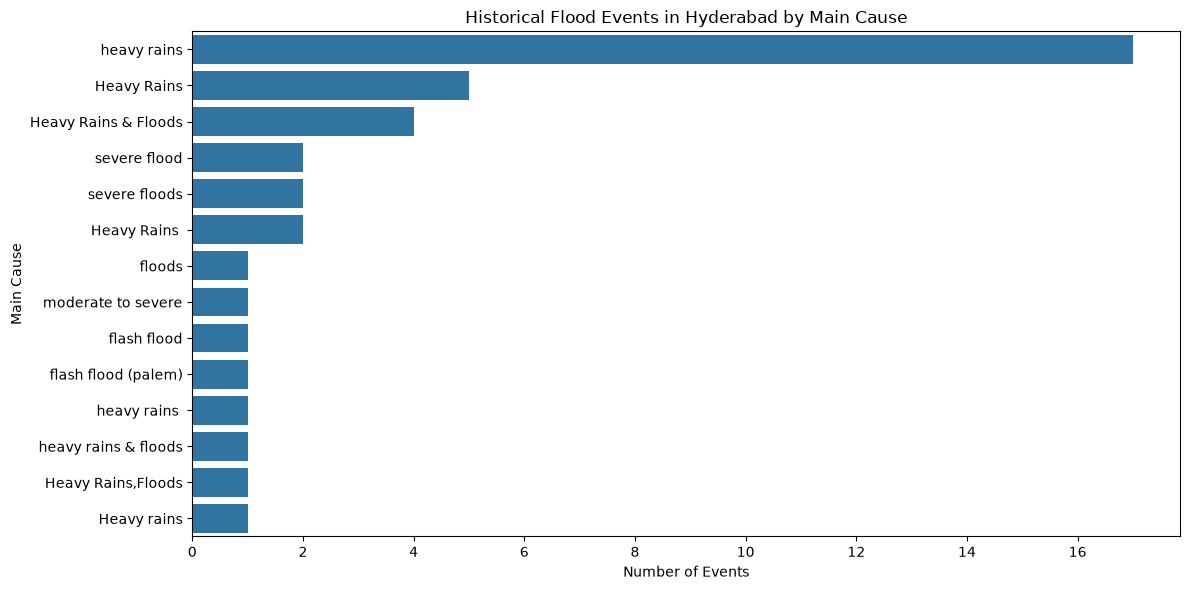

In [15]:
plt.figure(figsize=(12, 6))

cause_counts = (
    hyderabad_events["Main Cause"]
    .value_counts()
)

sns.barplot(
    x=cause_counts.values,
    y=cause_counts.index
)

plt.title("Historical Flood Events in Hyderabad by Main Cause")
plt.xlabel("Number of Events")
plt.ylabel("Main Cause")

plt.tight_layout()
plt.show()

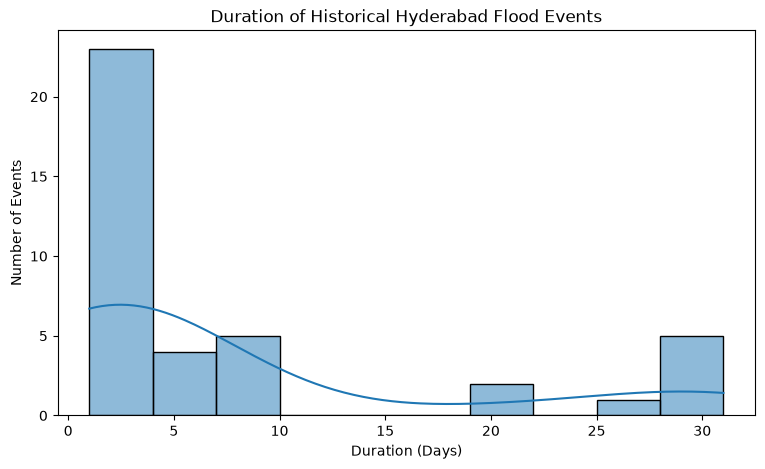

Average event duration: 7.725


In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=hyderabad_events,
    x="Duration(Days)",
    bins=10,
    kde=True
)

plt.title("Duration of Historical Hyderabad Flood Events")
plt.xlabel("Duration (Days)")
plt.ylabel("Number of Events")

plt.show()

print(
    "Average event duration:",
    hyderabad_events["Duration(Days)"].mean()
)

,Impact Type,Total
0,Human fatalities,727.0
1,Human injuries,20.0


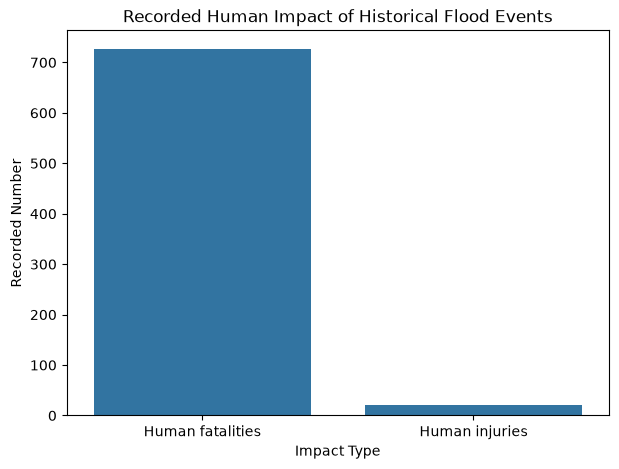

In [17]:
impact_data = hyderabad_events[
    ["Human fatality", "Human injured"]
].fillna(0)

impact_summary = pd.DataFrame({
    "Impact Type": ["Human fatalities", "Human injuries"],
    "Total": [
        impact_data["Human fatality"].sum(),
        impact_data["Human injured"].sum()
    ]
})

display(impact_summary)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=impact_summary,
    x="Impact Type",
    y="Total"
)

plt.title("Recorded Human Impact of Historical Flood Events")
plt.ylabel("Recorded Number")

plt.show()

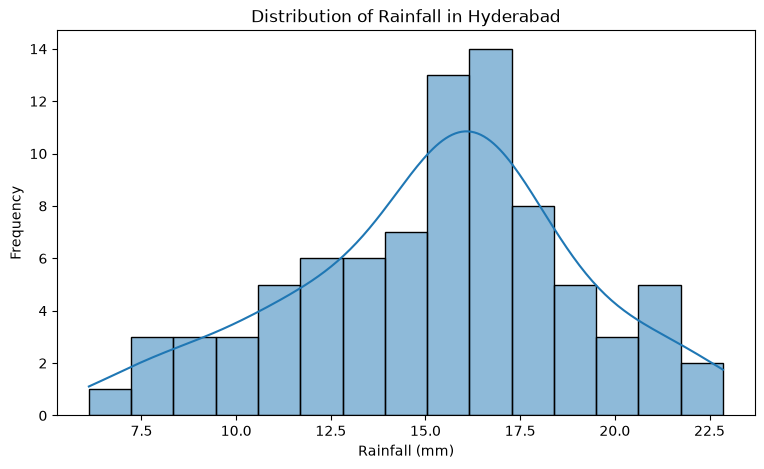

Average rainfall: 15.283190794047616
Maximum rainfall: 22.855469
Minimum rainfall: 6.110783


In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=rainfall_df,
    x="rainfall_mm",
    bins=15,
    kde=True
)

plt.title("Distribution of Rainfall in Hyderabad")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

print("Average rainfall:", rainfall_df["rainfall_mm"].mean())
print("Maximum rainfall:", rainfall_df["rainfall_mm"].max())
print("Minimum rainfall:", rainfall_df["rainfall_mm"].min())

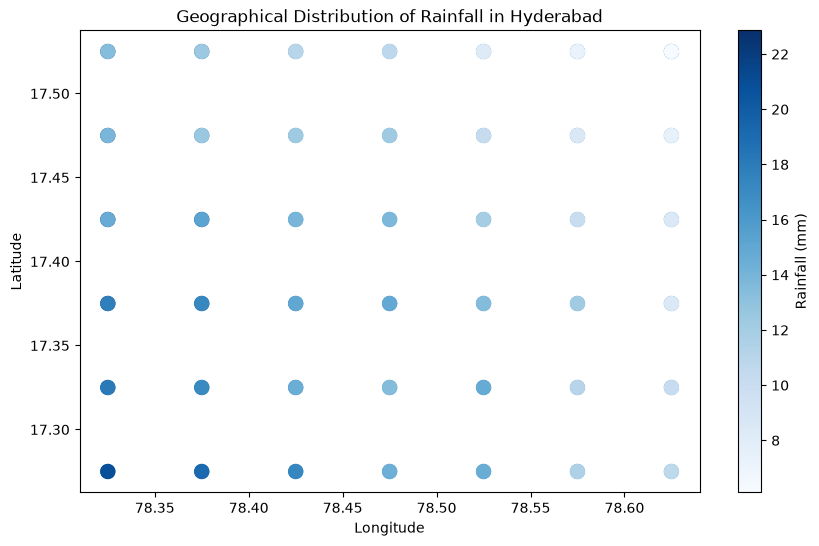

In [19]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rainfall_df["longitude"],
    rainfall_df["latitude"],
    c=rainfall_df["rainfall_mm"],
    cmap="Blues",
    s=100
)

plt.colorbar(
    scatter,
    label="Rainfall (mm)"
)

plt.title("Geographical Distribution of Rainfall in Hyderabad")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [20]:
cluster_features = rainfall_df[
    ["latitude", "longitude", "rainfall_mm"]
].copy()

scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    cluster_features
)

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rainfall_df["rainfall_cluster"] = kmeans.fit_predict(
    scaled_features
)

print("K-Means clustering completed!")

display(
    rainfall_df[
        [
            "date",
            "latitude",
            "longitude",
            "rainfall_mm",
            "rainfall_cluster"
        ]
    ].head(10)
)

K-Means clustering completed!


C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,date,latitude,longitude,rainfall_mm,rainfall_cluster
0,2020-09-25,17.525,78.325,21.588670,0
1,2020-09-25,17.525,78.375,20.557886,0
2,2020-09-25,17.525,78.425,16.716734,1
3,2020-09-25,17.525,78.475,15.319092,1
4,2020-09-25,17.525,78.525,16.243406,1
5,2020-09-25,17.525,78.575,16.762650,1
6,2020-09-25,17.525,78.625,18.223892,1
7,2020-09-25,17.475,78.325,21.703934,0
8,2020-09-25,17.475,78.375,19.723509,0
9,2020-09-25,17.475,78.425,16.078032,1


In [21]:
cluster_summary = rainfall_df.groupby(
    "rainfall_cluster"
).agg(
    total_records=("rainfall_mm", "count"),
    average_rainfall=("rainfall_mm", "mean"),
    minimum_rainfall=("rainfall_mm", "min"),
    maximum_rainfall=("rainfall_mm", "max")
).round(2)

display(cluster_summary)

,total_records,average_rainfall,minimum_rainfall,maximum_rainfall
rainfall_cluster,,,,
0,27,18.87,14.64,22.86
1,31,12.86,6.11,18.22
2,26,14.44,8.49,17.47


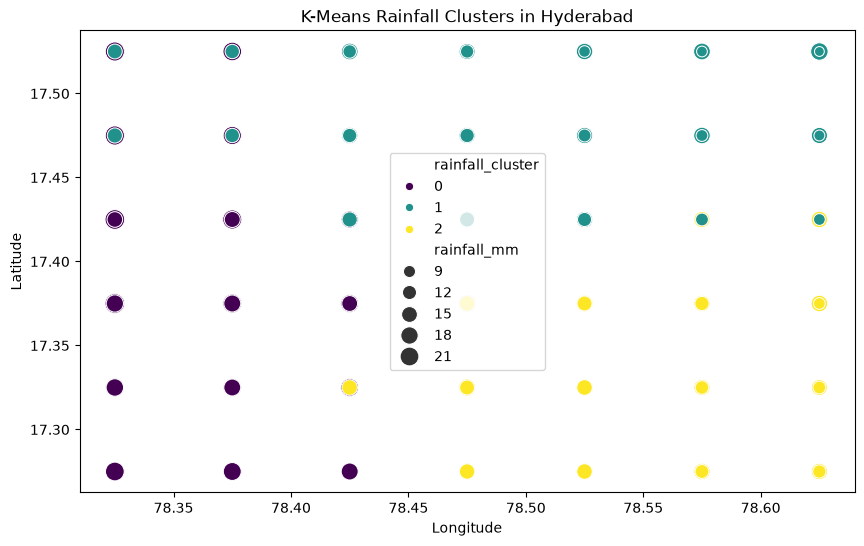

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rainfall_df,
    x="longitude",
    y="latitude",
    hue="rainfall_cluster",
    size="rainfall_mm",
    palette="viridis",
    sizes=(50, 200)
)

plt.title("K-Means Rainfall Clusters in Hyderabad")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

,average_rainfall,maximum_rainfall,minimum_rainfall
date,,,
2020-09-25,17.667686,22.855469,14.830524
2021-10-08,12.898695,20.921135,6.110783


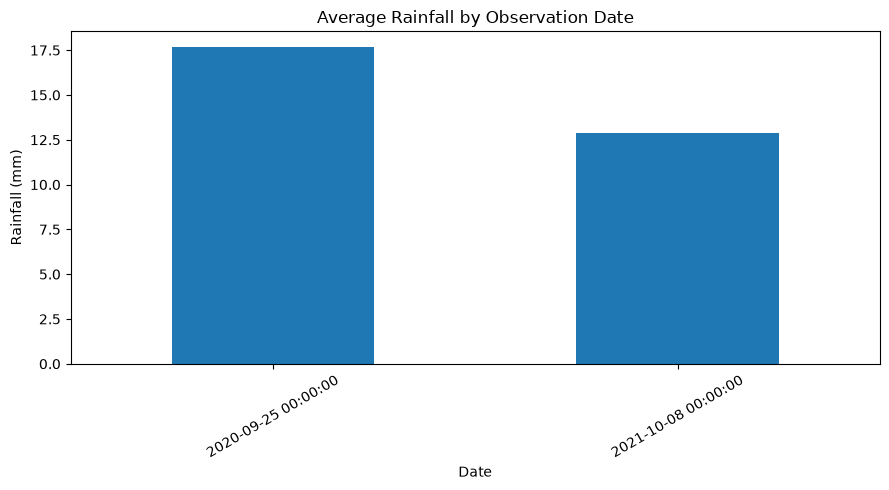

In [23]:
date_summary = rainfall_df.groupby("date").agg(
    average_rainfall=("rainfall_mm", "mean"),
    maximum_rainfall=("rainfall_mm", "max"),
    minimum_rainfall=("rainfall_mm", "min")
)

display(date_summary)

date_summary["average_rainfall"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Rainfall by Observation Date",
    ylabel="Rainfall (mm)",
    xlabel="Date"
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [24]:
output_dir = PROJECT_DIR / "flood_analysis_results"

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save cleaned rainfall data with cluster information
rainfall_df.to_csv(
    output_dir / "rainfall_analysis_results.csv",
    index=False
)

# Save historical Hyderabad events
hyderabad_events.to_csv(
    output_dir / "hyderabad_flood_events.csv",
    index=False
)

# Save date-wise event summary
event_summary.to_csv(
    output_dir / "flood_event_date_summary.csv",
    index=False
)

# Save clustering summary
cluster_summary.to_csv(
    output_dir / "rainfall_cluster_summary.csv"
)

# Save historical impact summary
impact_summary.to_csv(
    output_dir / "historical_flood_impact.csv",
    index=False
)

print("All analysis results saved successfully!")
print("Output folder:", output_dir)

All analysis results saved successfully!
Output folder: C:\Users\DELL\flood_analysis_results


In [25]:

# ==========================================
# STEP 5: FEATURE ENGINEERING
# ==========================================

# Create a separate copy
feature_df = rainfall_df.copy()

# 1. Convert date column into datetime
feature_df["date"] = pd.to_datetime(
    feature_df["date"],
    errors="coerce"
)

# 2. Extract date-related features
feature_df["month"] = feature_df["date"].dt.month
feature_df["day"] = feature_df["date"].dt.day
feature_df["day_of_year"] = feature_df["date"].dt.dayofyear

# 3. Create cyclical date features
feature_df["month_sin"] = np.sin(
    2 * np.pi * feature_df["month"] / 12
)

feature_df["month_cos"] = np.cos(
    2 * np.pi * feature_df["month"] / 12
)

feature_df["day_sin"] = np.sin(
    2 * np.pi * feature_df["day_of_year"] / 365.25
)

feature_df["day_cos"] = np.cos(
    2 * np.pi * feature_df["day_of_year"] / 365.25
)

# 4. Define supervised learning features
supervised_features = [
    "latitude",
    "longitude",
    "rainfall_mm",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos"
]

X_supervised = feature_df[supervised_features].copy()

# Target variable
y_supervised = feature_df["recorded_flood_event"].copy()

# 5. Define unsupervised learning features
unsupervised_features = [
    "latitude",
    "longitude",
    "rainfall_mm"
]

X_unsupervised = feature_df[
    unsupervised_features
].copy()

# 6. Display the engineered features
print("FEATURE ENGINEERING COMPLETED")

print("\nSupervised feature shape:")
print(X_supervised.shape)

print("\nUnsupervised feature shape:")
print(X_unsupervised.shape)

print("\nSupervised target distribution:")
print(y_supervised.value_counts())

print("\nEngineered feature dataset:")
display(feature_df.head())

print("\nSupervised features:")
display(X_supervised.head())

print("\nUnsupervised features:")
display(X_unsupervised.head())

# 7. Check whether supervised training is possible
print("\nNumber of target classes:", y_supervised.nunique())

if y_supervised.nunique() < 2:
    print(
        "\nWARNING: Only one target class is available."
        "\nSupervised classification cannot be trained "
        "reliably with the current labels."
    )
else:
    print(
        "\nBoth target classes are available."
        "\nWe can proceed to supervised model preparation."
    )


FEATURE ENGINEERING COMPLETED

Supervised feature shape:
(84, 7)

Unsupervised feature shape:
(84, 3)

Supervised target distribution:
recorded_flood_event
1    84
Name: count, dtype: int64

Engineered feature dataset:


,date,latitude,longitude,rainfall_mm,recorded_flood_event,rainfall_cluster,month,day,day_of_year,month_sin,month_cos,day_sin,day_cos
0,2020-09-25,17.525,78.325,21.588670,1,0,9,25,269,-1.0,-1.836970e-16,-0.996395,-0.084835
1,2020-09-25,17.525,78.375,20.557886,1,0,9,25,269,-1.0,-1.836970e-16,-0.996395,-0.084835
2,2020-09-25,17.525,78.425,16.716734,1,1,9,25,269,-1.0,-1.836970e-16,-0.996395,-0.084835
3,2020-09-25,17.525,78.475,15.319092,1,1,9,25,269,-1.0,-1.836970e-16,-0.996395,-0.084835
4,2020-09-25,17.525,78.525,16.243406,1,1,9,25,269,-1.0,-1.836970e-16,-0.996395,-0.084835



Supervised features:


,latitude,longitude,rainfall_mm,month_sin,month_cos,day_sin,day_cos
0,17.525,78.325,21.588670,-1.0,-1.836970e-16,-0.996395,-0.084835
1,17.525,78.375,20.557886,-1.0,-1.836970e-16,-0.996395,-0.084835
2,17.525,78.425,16.716734,-1.0,-1.836970e-16,-0.996395,-0.084835
3,17.525,78.475,15.319092,-1.0,-1.836970e-16,-0.996395,-0.084835
4,17.525,78.525,16.243406,-1.0,-1.836970e-16,-0.996395,-0.084835



Unsupervised features:


,latitude,longitude,rainfall_mm
0,17.525,78.325,21.588670
1,17.525,78.375,20.557886
2,17.525,78.425,16.716734
3,17.525,78.475,15.319092
4,17.525,78.525,16.243406



Number of target classes: 1

Supervised classification cannot be trained reliably with the current labels.


In [26]:

from pathlib import Path
import json

for notebook in Path(".").rglob("*.ipynb"):
    try:
        data = json.loads(notebook.read_text(encoding="utf-8"))

        for i, cell in enumerate(data.get("cells", [])):
            source = "".join(cell.get("source", []))

            if any(word in source.lower() for word in [
                "rainfall", "read_csv", "download",
                "requests.get", "https://"
            ]):
                print(f"\nFILE: {notebook}")
                print(f"CELL: {i}")
                print(source[:2000])

    except Exception:
        pass



FILE: Exercise 1.ipynb
CELL: 1
#task-1
df = pd.read_csv("hour.csv")

print("First Five Rows")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nDataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Values")
print(df.duplicated().sum())

print("\nStatistical Description")
print(df.describe())

df["dteday"] = pd.to_datetime(df["dteday"])

df = df.sort_values(
    ["dteday", "hr"]
).reset_index(drop=True)

print("\nDate Range")
print(df["dteday"].min())
print(df["dteday"].max())

print("\nTarget Range")
print(df["cnt"].min())
print(df["cnt"].max())

print("\nChecking Categorical Values")

for col in ["season", "mnth", "hr", "weekday", "weathersit"]:
    print(col, sorted(df[col].unique()))

print("\nDuplicate Rows:", df.duplicated().sum())

df["year_month"] = df["dteday"].dt.to_period("M")

print("\nMonthly Records")
print(df.groupby("year_month").size())

df = df.drop_duplicates().reset_index(drop=True)

df["day

In [27]:

from pathlib import Path

print("Current notebook location:")
print(Path.cwd())

print("\nSearching for flood inventory file...")

matches = list(
    Path.cwd().parents[0].rglob("India_Flood_Inventory_v3.csv")
)

# Also search the current directory
matches += list(
    Path.cwd().rglob("India_Flood_Inventory_v3.csv")
)

matches = list(set(matches))

if matches:
    print("\nFile found:")
    for file in matches:
        print(file)
else:
    print("\nFile not found. Check your project folder.")



Current notebook location:
C:\Users\DELL

Searching for flood inventory file...

File found:
C:\Users\DELL\India_Flood_Inventory_v3.csv
C:\Users\DELL\Downloads\India_Flood_Inventory_v3.csv
C:\Users\DELL\.vscode\urban-risk-analytics\data\raw\flood\India_Flood_Inventory_v3.csv


In [28]:

import pandas as pd
from pathlib import Path

matches = list(Path.cwd().parents[0].rglob(
    "India_Flood_Inventory_v3.csv"
))

matches += list(Path.cwd().rglob(
    "India_Flood_Inventory_v3.csv"
))

matches = list(set(matches))

if not matches:
    raise FileNotFoundError("Flood inventory CSV not found.")

flood_file = matches[0]

flood_inventory = pd.read_csv(flood_file)

print("Dataset loaded successfully!")
print("File location:", flood_file)
print("Dataset shape:", flood_inventory.shape)

print("\nColumn names:")
print(flood_inventory.columns.tolist())

print("\nFirst 10 records:")
display(flood_inventory.head(10))


Dataset loaded successfully!
File location: C:\Users\DELL\India_Flood_Inventory_v3.csv
Dataset shape: (6876, 23)

Column names:
['Unnamed: 0', 'UEI', 'Start Date', 'End Date', 'Duration(Days)', 'Main Cause', 'Location', 'Districts', 'State', 'Latitude', 'Longitude', 'Severity', 'Area Affected', 'Human fatality', 'Human injured', 'Human Displaced', 'Animal Fatality', 'Description of Casualties/injured', 'Extent of damage ', 'Event Source', 'Event Souce ID', 'District_LGD_Codes', 'State_Codes']

First 10 records:


,Unnamed: 0,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,...,Human fatality,Human injured,Human Displaced,Animal Fatality,Description of Casualties/injured,Extent of damage,Event Source,Event Souce ID,District_LGD_Codes,State_Codes
0,563,UEI-IMD-FL-1967-0001,02-07-1967 00:00,08-07-1967 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,18
1,564,UEI-IMD-FL-1967-0002,22-07-1967 00:00,28-07-1967 00:00,7.0,flood,NaN,NaN,"Maharashtra, Gujarat",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,"27,24"
2,565,UEI-IMD-FL-1967-0003,01-08-1967 00:00,30-08-1967 00:00,30.0,flood,NaN,NaN,Uttar Pradesh,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,9
3,566,UEI-IMD-FL-1967-0004,08-09-1967 00:00,09-09-1967 00:00,2.0,flood,NaN,"Bhadrak, Dhenkanal, Jajapur, Subarnapur, Nuapa...","Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, ...",NaN,...,NaN,NaN,NaN,NaN,NaN,Marooning of Barwer Express,IMD,NaN,"348, 352, 356, None, 368, 345, 349, 350, 359, ...","21,10,9,23,8,6"
4,567,UEI-IMD-FL-1968-0001,22-06-1968 00:00,28-06-1968 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,"Affecting about one million people,an area of ...",IMD,NaN,NaN,18
5,568,UEI-IMD-FL-1968-0002,08-06-1968 00:00,12-06-1968 00:00,5.0,"heavy rains, floods",NaN,NaN,West Bengal,NaN,...,NaN,NaN,NaN,NaN,NaN,"Causing floods in West Bengal, Kolkata recieve...",IMD,NaN,NaN,19
6,569,UEI-IMD-FL-1968-0003,01-07-1968 00:00,30-07-1968 00:00,30.0,floods,NaN,"Kasaragod, Wayanad, Kozhikode, Malappuram, Pal...","Kerala, Rajasthan, Haryana, Uttar Pradesh, Bihar",NaN,...,NaN,NaN,NaN,NaN,NaN,One passenger train was marooned in flood wate...,IMD,NaN,"558, 567, 561, 562, 563, 566, 556, 555, 554, 5...","32,8,6,9,10"
7,570,UEI-IMD-FL-1968-0004,18-07-1968 00:00,18-07-1968 00:00,1.0,cloud burst,NaN,NaN,Uttar Pradesh,NaN,...,NaN,NaN,NaN,NaN,NaN,Completely wiped out,IMD,NaN,NaN,9
8,571,UEI-IMD-FL-1968-0005,01-08-1968 00:00,08-08-1968 00:00,8.0,severe floods,NaN,Surat,Gujarat,NaN,...,NaN,NaN,NaN,NaN,NaN,Rail amd road communications with Mumbai were ...,IMD,NaN,459,24
9,572,UEI-IMD-FL-1968-0006,01-10-1968 00:00,08-10-1968 00:00,8.0,floods,NaN,"Darjeeling, Jalpaiguri, Cooch Behar",West Bengal,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,"309, 314, 308",19


In [29]:

# STEP 1: Inspect flood events in Telangana

# Check all state names
print("Available states:")
print(
    flood_inventory["State"]
    .dropna()
    .unique()
)

# Filter Telangana records
telangana_floods = flood_inventory[
    flood_inventory["State"]
    .astype(str)
    .str.contains("Telangana", case=False, na=False)
].copy()

print("\nTelangana flood records:")
print("Total:", len(telangana_floods))

display(
    telangana_floods[
        ["Start Date", "End Date", "Main Cause",
         "Districts", "State", "Latitude", "Longitude"]
    ].head(15)
)


Available states:
<ArrowStringArray>
[                                                                'Assam',
                                                  'Maharashtra, Gujarat',
                                                         'Uttar Pradesh',
      'Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, Rajasthan, Haryana',
                                                           'West Bengal',
                      'Kerala, Rajasthan, Haryana, Uttar Pradesh, Bihar',
                                                               'Gujarat',
                                                                'Sikkim',
                                                        'Andhra Pradesh',
                                                     'Karnataka, Kerala',
                                                     'Odisha, Rajasthan',
                                       'Himachal Pradesh, Uttar Pradesh',
                                      'Jammu and Kashmir, Delhi, Punjab',
 

,Start Date,End Date,Main Cause,Districts,State,Latitude,Longitude
19,15-09-1969 00:00,22-09-1969 00:00,floods,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...","Maharashtra, Telangana",NaN,NaN
31,22-09-1970 00:00,22-09-1970 00:00,torrential rain,NaN,Telangana,NaN,NaN
128,01-07-1976 00:00,07-07-1976 00:00,flash floods,"Khammam, Bhadradri Bhadradri Kothagudem kothag...",Telangana,NaN,NaN
3163,08-08-2008 00:00,14-08-2008 00:00,flash flood (palem),"Adilabad, Y.S.R., East Godavari, Guntur, Hyder...","Andhra Pradesh, Telangana",NaN,NaN
3926,06-09-2014 00:00,09-09-2014 00:00,heavy rains,"Adilabad, Khammam, Karimnagar,Warangal, Warang...",Telangana,NaN,NaN
3927,27-10-2014 00:00,27-10-2014 00:00,heavy rains,Nalgonda,Telangana,NaN,NaN
4031,06-09-2015 00:00,12-09-2015 00:00,heavy rains,"Adilabad, Karimnagar, Khammam, Medak, Nalgonda...",Telangana,NaN,NaN
4156,02-03-2016 00:00,02-03-2016 00:00,heavy rains,"Karimnagar, Khammam, Nizamabad, Warangal, Wara...",Telangana,NaN,NaN
4157,31-08-2016 00:00,31-08-2016 00:00,heavy rains,Hyderabad,Telangana,NaN,NaN
4158,01-09-2016 00:00,30-09-2016 00:00,heavy rains & floods,"Hyderabad, Kamareddy, Karimnagar, Medak, Medch...",Telangana,NaN,NaN


In [30]:

# STEP 1: Extract Hyderabad-specific flood records

hyderabad_floods = flood_inventory[
    flood_inventory["Districts"].astype(str).str.contains(
        "Hyderabad", case=False, na=False
    )
].copy()

# Convert dates into proper datetime format
hyderabad_floods["Start Date"] = pd.to_datetime(
    hyderabad_floods["Start Date"],
    dayfirst=True,
    errors="coerce"
)

hyderabad_floods["End Date"] = pd.to_datetime(
    hyderabad_floods["End Date"],
    dayfirst=True,
    errors="coerce"
)

print("HYDERABAD FLOOD RECORDS")
print("Total records:", len(hyderabad_floods))

display(
    hyderabad_floods[
        [
            "Start Date",
            "End Date",
            "Duration(Days)",
            "Main Cause",
            "Districts",
            "State"
        ]
    ].sort_values("Start Date")
)


HYDERABAD FLOOD RECORDS
Total records: 40


,Start Date,End Date,Duration(Days),Main Cause,Districts,State
19,1969-09-15,1969-09-22,8.0,floods,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...","Maharashtra, Telangana"
99,1975-08-01,1975-08-27,27.0,heavy rains,"Krishna, Srikakulam,Hyderabad",Karnataka
134,1978-08-01,1978-08-21,21.0,moderate to severe,"West Godavari, Guntur, nalgonda, Khammam,Praka...",Andhra Pradesh
481,1983-09-23,1983-09-23,1.0,heavy rains,"Hyderabad, Kurnool, Mahabubnagar",Andhra Pradesh
688,1985-10-05,1985-10-05,1.0,heavy rains,Hyderabad,Andhra Pradesh
763,1986-01-17,1986-01-17,1.0,heavy rains,Hyderabad,Andhra Pradesh
765,1986-06-16,1986-06-16,1.0,heavy rains,Hyderabad,Andhra Pradesh
1158,1991-06-18,1991-06-18,1.0,heavy rains,Hyderabad,Andhra Pradesh
1374,1993-10-07,1993-10-11,5.0,flash flood,"Hyderabad, Kurnool,Mahabubnagar",Andhra Pradesh
1473,1994-10-04,1994-10-06,3.0,heavy rains,"Y.S.R., Hyderabad, Krishna, Kurnool, Mahabubna...",Andhra Pradesh


In [31]:

print("Hyderabad flood events by year:")

print(
    hyderabad_floods["Start Date"]
    .dt.year
    .value_counts()
    .sort_index()
)


Hyderabad flood events by year:
Start Date
1969     1
1975     1
1978     1
1983     1
1985     1
1986     2
1991     1
1993     1
1994     1
1996     2
1997     1
2000     2
2005     1
2007     2
2008     3
2012     2
2013     2
2016     2
2020     2
2021     1
2022    10
Name: count, dtype: int64


In [32]:

# Display all Hyderabad flood event details

columns_to_show = [
    "Start Date",
    "End Date",
    "Duration(Days)",
    "Main Cause",
    "Districts",
    "State",
    "Event Source"
]

# Keep only columns that actually exist
columns_to_show = [
    col for col in columns_to_show
    if col in hyderabad_floods.columns
]

display(
    hyderabad_floods[columns_to_show]
    .sort_values("Start Date")
    .to_string(index=False)
)


'Start Date   End Date  Duration(Days)           Main Cause                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         Districts                     State Event Source\n1969-09-15 1969-09

In [33]:

recent_floods = hyderabad_floods[
    hyderabad_floods["Start Date"].dt.year.between(2020, 2022)
]

print("Hyderabad flood events (2020–2022):")
display(recent_floods)


Hyderabad flood events (2020–2022):


,Unnamed: 0,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,...,Human fatality,Human injured,Human Displaced,Animal Fatality,Description of Casualties/injured,Extent of damage,Event Source,Event Souce ID,District_LGD_Codes,State_Codes
4725,5288,UEI-IMD-FL-2020-0132,2020-09-25,2020-09-25,1.0,Heavy rains,NaN,Hyderabad,Telangana,NaN,...,1.0,NaN,NaN,NaN,One person died.,NaN,IMD,NaN,507,36
4726,5289,UEI-IMD-FL-2020-0133,2020-01-10,2020-10-20,20.0,"Heavy Rains,Floods",NaN,Hyderabad & Parts of Telangana,Telangana,NaN,...,61.0,NaN,6,NaN,"Total 61 persons died, 6 missing & several oth...",i) Hyderabad Municipal Corporation area worst ...,IMD,NaN,NaN,36
5032,5595,UEI-IMD-FL-2021-0286,2021-10-08,2021-10-08,1.0,Heavy Rains & Floods,NaN,Hyderabad,Telangana,NaN,...,2.0,NaN,NaN,NaN,NaN,NaN,IMD,NaN,507,36
5923,6486,UEI-IMD-FL-2022-0840,2022-06-16,2022-06-17,2.0,Heavy Rains,NaN,Hyderabad,Telangana,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,507,36
5930,6493,UEI-IMD-FL-2022-0847,2022-06-19,2022-06-20,2.0,Heavy Rains,NaN,Hyderabad,Telangana,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,507,36
5953,6516,UEI-IMD-FL-2022-0870,2022-07-10,2022-07-10,1.0,Heavy Rains,NaN,Hyderabad,Telangana,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,507,36
5959,6522,UEI-IMD-FL-2022-0876,2022-07-11,2022-07-11,1.0,Heavy Rains & Floods,NaN,Hyderabad,Telangana,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,507,36
5993,6556,UEI-IMD-FL-2022-0910,2022-07-23,2022-07-29,7.0,Heavy Rains,NaN,Hyderabad,Telangana,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,507,36
6012,6575,UEI-IMD-FL-2022-0929,2022-09-27,2022-09-29,3.0,Heavy Rains,NaN,Hyderabad,Telangana,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,507,36
6014,6577,UEI-IMD-FL-2022-0931,2022-09-01,2022-09-30,30.0,Heavy Rains & Floods,NaN,Hyderabad,Telangana,NaN,...,NaN,2.0,NaN,NaN,NaN,NaN,IMD,NaN,507,36


In [34]:

# Extract and validate Hyderabad flood event dates

events = hyderabad_floods.copy()

events["Start Date"] = pd.to_datetime(
    events["Start Date"], errors="coerce"
)
events["End Date"] = pd.to_datetime(
    events["End Date"], errors="coerce"
)

events["Duration(Days)"] = pd.to_numeric(
    events["Duration(Days)"], errors="coerce"
)

# Check date-range consistency
events["Calculated_Days"] = (
    events["End Date"] - events["Start Date"]
).dt.days + 1

invalid_events = events[
    events["Duration(Days)"].notna() &
    (events["Calculated_Days"] != events["Duration(Days)"])
]

print("Records requiring date verification:")
display(invalid_events[
    ["Start Date", "End Date", "Duration(Days)", "Calculated_Days"]
])

# Keep only valid date ranges
valid_events = events[
    events["Start Date"].notna() &
    events["End Date"].notna() &
    (events["End Date"] >= events["Start Date"]) &
    (events["Calculated_Days"] == events["Duration(Days)"])
].copy()

# Generate documented event dates
event_dates = sorted(set(
    date
    for _, row in valid_events.iterrows()
    for date in pd.date_range(
        row["Start Date"], row["End Date"]
    )
))

print("\nTotal valid documented event dates:", len(event_dates))
print("\nEvent dates:")
print(pd.Series(event_dates))


Records requiring date verification:


,Start Date,End Date,Duration(Days),Calculated_Days
4726,2020-01-10,2020-10-20,20.0,285



Total valid documented event dates: 286

Event dates:
0     1969-09-15
1     1969-09-16
2     1969-09-17
3     1969-09-18
4     1969-09-19
         ...    
281   2022-11-26
282   2022-11-27
283   2022-11-28
284   2022-11-29
285   2022-11-30
Length: 286, dtype: datetime64[us]


In [35]:

# Keep valid flood events from 1981 onwards

chirps_events = valid_events[
    valid_events["Start Date"].dt.year >= 1981
].copy()

# Generate unique flood dates
chirps_flood_dates = sorted(set(
    date
    for _, row in chirps_events.iterrows()
    for date in pd.date_range(
        row["Start Date"], row["End Date"]
    )
))

print("Valid flood events:", len(chirps_events))
print("Unique flood dates:", len(chirps_flood_dates))
print("Date range:", chirps_flood_dates[0],
      "to", chirps_flood_dates[-1])


Valid flood events: 36
Unique flood dates: 230
Date range: 1983-09-23 00:00:00 to 2022-11-30 00:00:00


In [36]:

from pathlib import Path

output_folder = Path("data/processed/flood")
output_folder.mkdir(parents=True, exist_ok=True)

pd.DataFrame({
    "date": chirps_flood_dates,
    "recorded_flood_event": 1
}).to_csv(
    output_folder / "hyderabad_verified_flood_dates.csv",
    index=False
)

print("Flood dates saved successfully!")


Flood dates saved successfully!


In [37]:

# ==========================================
# STEP 5: FEATURE ENGINEERING
# ==========================================

import pandas as pd
import numpy as np
from pathlib import Path

print("Starting Feature Engineering...")

# Create a copy of the cleaned rainfall dataset
feature_df = rainfall_df.copy()

# Make sure date is in datetime format
feature_df["date"] = pd.to_datetime(
    feature_df["date"],
    errors="coerce"
)

# Remove records with missing essential values
feature_df = feature_df.dropna(
    subset=["date", "latitude", "longitude", "rainfall_mm"]
)

# ------------------------------------------
# 1. Create date-based features
# ------------------------------------------

feature_df["year"] = feature_df["date"].dt.year
feature_df["month"] = feature_df["date"].dt.month
feature_df["day"] = feature_df["date"].dt.day

# ------------------------------------------
# 2. Create rainfall intensity features
# ------------------------------------------

# Log transformation reduces the effect of
# highly skewed rainfall values
feature_df["log_rainfall"] = np.log1p(
    feature_df["rainfall_mm"].clip(lower=0)
)

# ------------------------------------------
# 3. Aggregate rainfall by observation date
# ------------------------------------------

daily_features = feature_df.groupby("date").agg(

    average_rainfall=("rainfall_mm", "mean"),

    maximum_rainfall=("rainfall_mm", "max"),

    minimum_rainfall=("rainfall_mm", "min"),

    median_rainfall=("rainfall_mm", "median"),

    rainfall_std=("rainfall_mm", "std"),

    rainfall_90th_percentile=(
        "rainfall_mm",
        lambda x: x.quantile(0.90)
    ),

    total_grid_observations=("rainfall_mm", "count"),

    average_latitude=("latitude", "mean"),

    average_longitude=("longitude", "mean")

).reset_index()

# ------------------------------------------
# 4. Add calendar features to daily dataset
# ------------------------------------------

daily_features["year"] = daily_features["date"].dt.year
daily_features["month"] = daily_features["date"].dt.month
daily_features["day"] = daily_features["date"].dt.day

# ------------------------------------------
# 5. Display engineered features
# ------------------------------------------

print("\nSpatial feature dataset:")
display(feature_df.head())

print("\nDaily engineered feature dataset:")
display(daily_features)

print("\nFeature columns:")
print(daily_features.columns.tolist())

print("\nNumber of spatial records:", len(feature_df))
print("Number of unique dates:", len(daily_features))

# ------------------------------------------
# 6. Save engineered datasets
# ------------------------------------------

output_dir = PROJECT_DIR / "flood_analysis_results"

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

feature_df.to_csv(
    output_dir / "rainfall_engineered.csv",
    index=False
)

daily_features.to_csv(
    output_dir / "daily_rainfall_features.csv",
    index=False
)

print("\nFeature Engineering completed!")
print("Files saved successfully in:", output_dir)


Starting Feature Engineering...

Spatial feature dataset:


,date,latitude,longitude,rainfall_mm,recorded_flood_event,rainfall_cluster,year,month,day,log_rainfall
0,2020-09-25,17.525,78.325,21.588670,1,0,2020,9,25,3.117448
1,2020-09-25,17.525,78.375,20.557886,1,0,2020,9,25,3.070742
2,2020-09-25,17.525,78.425,16.716734,1,1,2020,9,25,2.874510
3,2020-09-25,17.525,78.475,15.319092,1,1,2020,9,25,2.792336
4,2020-09-25,17.525,78.525,16.243406,1,1,2020,9,25,2.847430



Daily engineered feature dataset:


,date,average_rainfall,maximum_rainfall,minimum_rainfall,median_rainfall,rainfall_std,rainfall_90th_percentile,total_grid_observations,average_latitude,average_longitude,year,month,day
0,2020-09-25,17.667686,22.855469,14.830524,16.716737,2.220304,21.531556,42,17.4,78.475,2020,9,25
1,2021-10-08,12.898695,20.921135,6.110783,12.945910,3.390219,17.296173,42,17.4,78.475,2021,10,8



Feature columns:
['date', 'average_rainfall', 'maximum_rainfall', 'minimum_rainfall', 'median_rainfall', 'rainfall_std', 'rainfall_90th_percentile', 'total_grid_observations', 'average_latitude', 'average_longitude', 'year', 'month', 'day']

Number of spatial records: 84
Number of unique dates: 2

Feature Engineering completed!
Files saved successfully in: C:\Users\DELL\flood_analysis_results


FEATURE VALIDATION


In [38]:

# ==========================================
# STEP 5 (CONTINUED): FEATURE VALIDATION
# ==========================================

print("Starting Feature Validation...")

# 1. Check spatial feature dataset
print("\n1. SPATIAL DATASET CHECK")

print("Total records:", len(feature_df))
print("Duplicate records:", feature_df.duplicated().sum())

print("\nMissing values:")
display(feature_df.isnull().sum())

print("\nRainfall statistics:")
display(feature_df["rainfall_mm"].describe())

# 2. Check daily feature dataset
print("\n2. DAILY FEATURE DATASET CHECK")

print("Total daily records:", len(daily_features))
print("Duplicate dates:", daily_features["date"].duplicated().sum())

print("\nMissing values:")
display(daily_features.isnull().sum())

# 3. Add verified event labels to daily features
daily_target = (
    feature_df.groupby("date")["recorded_flood_event"]
    .max()
    .reset_index()
)

# Avoid creating duplicate target columns
daily_features = daily_features.drop(
    columns=["recorded_flood_event"],
    errors="ignore"
)

daily_features = daily_features.merge(
    daily_target,
    on="date",
    how="left",
    validate="one_to_one"
)

# 4. Check target distribution
print("\n3. TARGET VARIABLE VALIDATION")

target_counts = daily_features[
    "recorded_flood_event"
].value_counts().sort_index()

print(target_counts)

print("\nNumber of target classes:",
      daily_features["recorded_flood_event"].nunique())

# 5. Check whether data is ready for supervised learning
if daily_features["recorded_flood_event"].nunique() < 2:

    print("\nWARNING: Supervised classification is NOT ready.")
    print("Only one target class is currently available.")
    print("Verified non-flood observations are required.")

else:

    print("\nBoth target classes are available.")

# 6. Final validation summary
validation_summary = pd.DataFrame({
    "Check": [
        "Spatial records",
        "Unique dates",
        "Duplicate spatial records",
        "Duplicate daily dates",
        "Missing daily feature values",
        "Target classes"
    ],
    "Result": [
        len(feature_df),
        daily_features["date"].nunique(),
        feature_df.duplicated().sum(),
        daily_features["date"].duplicated().sum(),
        daily_features.isnull().sum().sum(),
        daily_features["recorded_flood_event"].nunique()
    ]
})

print("\n4. FINAL VALIDATION SUMMARY")
display(validation_summary)

# 7. Save validated dataset
output_dir = PROJECT_DIR / "flood_analysis_results"
output_dir.mkdir(parents=True, exist_ok=True)

daily_features.to_csv(
    output_dir / "daily_rainfall_features.csv",
    index=False
)

validation_summary.to_csv(
    output_dir / "feature_validation_report.csv",
    index=False
)

print("\nFeature validation completed!")
print("Validated files saved in:", output_dir)


Starting Feature Validation...

1. SPATIAL DATASET CHECK
Total records: 84
Duplicate records: 0

Missing values:


date                    0
latitude                0
longitude               0
rainfall_mm             0
recorded_flood_event    0
rainfall_cluster        0
year                    0
month                   0
day                     0
log_rainfall            0
dtype: int64


Rainfall statistics:


count    84.000000
mean     15.283191
std       3.723850
min       6.110783
25%      13.146634
50%      15.825913
75%      17.373213
max      22.855469
Name: rainfall_mm, dtype: float64


2. DAILY FEATURE DATASET CHECK
Total daily records: 2
Duplicate dates: 0

Missing values:


date                        0
average_rainfall            0
maximum_rainfall            0
minimum_rainfall            0
median_rainfall             0
rainfall_std                0
rainfall_90th_percentile    0
total_grid_observations     0
average_latitude            0
average_longitude           0
year                        0
month                       0
day                         0
dtype: int64


3. TARGET VARIABLE VALIDATION
recorded_flood_event
1    2
Name: count, dtype: int64

Number of target classes: 1

Only one target class is currently available.
Verified non-flood observations are required.

4. FINAL VALIDATION SUMMARY


,Check,Result
0,Spatial records,84
1,Unique dates,2
2,Duplicate spatial records,0
3,Duplicate daily dates,0
4,Missing daily feature values,0
5,Target classes,1



Feature validation completed!
Validated files saved in: C:\Users\DELL\flood_analysis_results


In [39]:

# ==========================================
# NEXT STEP: INSPECT SAVED FLOOD DATE FILES
# ==========================================

from pathlib import Path
import pandas as pd

print("SEARCHING FOR SAVED FLOOD DATE DATASETS...")

# Search all CSV files in the project
all_csv_files = list(PROJECT_DIR.rglob("*.csv"))

print("\nTotal CSV files found:", len(all_csv_files))

candidate_files = []

for file in all_csv_files:

    try:
        # Read only column names first
        columns = pd.read_csv(file, nrows=0).columns.tolist()

        # Look for possible flood-date datasets
        filename = file.name.lower()

        date_columns = [
            col for col in columns
            if "date" in col.lower()
        ]

        if (
            ("flood" in filename or "date" in filename)
            and date_columns
        ):
            candidate_files.append(file)

    except Exception as error:
        print("Could not inspect:", file.name, error)


# Display candidate datasets
print("\n========== FLOOD DATE FILES ==========")

for file in candidate_files:

    df_check = pd.read_csv(file)

    print("\nFile:", file.name)
    print("Location:", file)
    print("Records:", len(df_check))
    print("Columns:", df_check.columns.tolist())

    date_columns = [
        col for col in df_check.columns
        if "date" in col.lower()
    ]

    for col in date_columns:

        dates = pd.to_datetime(
            df_check[col],
            errors="coerce"
        ).dropna()

        print("\nDate column:", col)
        print("Valid dates:", len(dates))

        if not dates.empty:
            print("Earliest date:", dates.min())
            print("Latest date:", dates.max())

    display(df_check.head(5))


if not candidate_files:
    print("\nNo matching flood-date CSV files found.")
    print("Please check where your corrected dates were saved.")

print("\nFLOOD DATE INSPECTION COMPLETED!")


SEARCHING FOR SAVED FLOOD DATE DATASETS...

Total CSV files found: 636
Could not inspect: t.csv No columns to parse from file

========== FLOOD DATE FILES ==========

File: India_Flood_Inventory_v3.csv
Location: C:\Users\DELL\India_Flood_Inventory_v3.csv
Records: 6876
Columns: ['Unnamed: 0', 'UEI', 'Start Date', 'End Date', 'Duration(Days)', 'Main Cause', 'Location', 'Districts', 'State', 'Latitude', 'Longitude', 'Severity', 'Area Affected', 'Human fatality', 'Human injured', 'Human Displaced', 'Animal Fatality', 'Description of Casualties/injured', 'Extent of damage ', 'Event Source', 'Event Souce ID', 'District_LGD_Codes', 'State_Codes']

Date column: Start Date
Valid dates: 2930
Earliest date: 1967-01-08 00:00:00
Latest date: 2023-12-09 00:00:00

Date column: End Date
Valid dates: 2422
Earliest date: 1967-08-07 00:00:00
Latest date: 2023-12-09 00:00:00


,Unnamed: 0,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,...,Human fatality,Human injured,Human Displaced,Animal Fatality,Description of Casualties/injured,Extent of damage,Event Source,Event Souce ID,District_LGD_Codes,State_Codes
0,563,UEI-IMD-FL-1967-0001,02-07-1967 00:00,08-07-1967 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,18
1,564,UEI-IMD-FL-1967-0002,22-07-1967 00:00,28-07-1967 00:00,7.0,flood,NaN,NaN,"Maharashtra, Gujarat",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,"27,24"
2,565,UEI-IMD-FL-1967-0003,01-08-1967 00:00,30-08-1967 00:00,30.0,flood,NaN,NaN,Uttar Pradesh,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,9
3,566,UEI-IMD-FL-1967-0004,08-09-1967 00:00,09-09-1967 00:00,2.0,flood,NaN,"Bhadrak, Dhenkanal, Jajapur, Subarnapur, Nuapa...","Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, ...",NaN,...,NaN,NaN,NaN,NaN,NaN,Marooning of Barwer Express,IMD,NaN,"348, 352, 356, None, 368, 345, 349, 350, 359, ...","21,10,9,23,8,6"
4,567,UEI-IMD-FL-1968-0001,22-06-1968 00:00,28-06-1968 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,"Affecting about one million people,an area of ...",IMD,NaN,NaN,18



File: India_Flood_Inventory_v3-checkpoint.csv
Location: C:\Users\DELL\.ipynb_checkpoints\India_Flood_Inventory_v3-checkpoint.csv
Records: 6876
Columns: ['Unnamed: 0', 'UEI', 'Start Date', 'End Date', 'Duration(Days)', 'Main Cause', 'Location', 'Districts', 'State', 'Latitude', 'Longitude', 'Severity', 'Area Affected', 'Human fatality', 'Human injured', 'Human Displaced', 'Animal Fatality', 'Description of Casualties/injured', 'Extent of damage ', 'Event Source', 'Event Souce ID', 'District_LGD_Codes', 'State_Codes']

Date column: Start Date
Valid dates: 2930
Earliest date: 1967-01-08 00:00:00
Latest date: 2023-12-09 00:00:00

Date column: End Date
Valid dates: 2422
Earliest date: 1967-08-07 00:00:00
Latest date: 2023-12-09 00:00:00


,Unnamed: 0,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,...,Human fatality,Human injured,Human Displaced,Animal Fatality,Description of Casualties/injured,Extent of damage,Event Source,Event Souce ID,District_LGD_Codes,State_Codes
0,563,UEI-IMD-FL-1967-0001,02-07-1967 00:00,08-07-1967 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,18
1,564,UEI-IMD-FL-1967-0002,22-07-1967 00:00,28-07-1967 00:00,7.0,flood,NaN,NaN,"Maharashtra, Gujarat",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,"27,24"
2,565,UEI-IMD-FL-1967-0003,01-08-1967 00:00,30-08-1967 00:00,30.0,flood,NaN,NaN,Uttar Pradesh,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,9
3,566,UEI-IMD-FL-1967-0004,08-09-1967 00:00,09-09-1967 00:00,2.0,flood,NaN,"Bhadrak, Dhenkanal, Jajapur, Subarnapur, Nuapa...","Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, ...",NaN,...,NaN,NaN,NaN,NaN,NaN,Marooning of Barwer Express,IMD,NaN,"348, 352, 356, None, 368, 345, 349, 350, 359, ...","21,10,9,23,8,6"
4,567,UEI-IMD-FL-1968-0001,22-06-1968 00:00,28-06-1968 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,"Affecting about one million people,an area of ...",IMD,NaN,NaN,18



File: hyderabad_historical_flood_events.csv
Location: C:\Users\DELL\data\hyderabad_historical_flood_events.csv
Records: 40
Columns: ['UEI', 'Start Date', 'End Date', 'Start_Date_Parsed', 'End_Date_Parsed', 'Main Cause', 'Districts', 'State', 'Duration(Days)', 'Human fatality', 'Human injured']

Date column: Start Date
Valid dates: 40
Earliest date: 1969-09-15 00:00:00
Latest date: 2022-11-01 00:00:00

Date column: End Date
Valid dates: 40
Earliest date: 1969-09-22 00:00:00
Latest date: 2022-11-30 00:00:00

Date column: Start_Date_Parsed
Valid dates: 40
Earliest date: 1969-09-15 00:00:00
Latest date: 2022-11-01 00:00:00

Date column: End_Date_Parsed
Valid dates: 40
Earliest date: 1969-09-22 00:00:00
Latest date: 2022-11-30 00:00:00


C:\Users\DELL\AppData\Local\Temp\ipykernel_7700\3383744171.py:60: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dates = pd.to_datetime(
C:\Users\DELL\AppData\Local\Temp\ipykernel_7700\3383744171.py:60: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dates = pd.to_datetime(


... (17 outputs left out)


File: hyderabad_historical_flood_events.csv
Location: C:\Users\DELL\.vscode\urban-risk-analytics\data\processed\flood\dataset\hyderabad_historical_flood_events.csv
Records: 40
Columns: ['UEI', 'Start Date', 'End Date', 'Start_Date_Parsed', 'End_Date_Parsed', 'Main Cause', 'Districts', 'State', 'Duration(Days)', 'Human fatality', 'Human injured']

Date column: Start Date
Valid dates: 40
Earliest date: 1969-09-15 00:00:00
Latest date: 2022-11-01 00:00:00

Date column: End Date
Valid dates: 40
Earliest date: 1969-09-22 00:00:00
Latest date: 2022-11-30 00:00:00

Date column: Start_Date_Parsed
Valid dates: 40
Earliest date: 1969-09-15 00:00:00
Latest date: 2022-11-01 00:00:00

Date column: End_Date_Parsed
Valid dates: 40
Earliest date: 1969-09-22 00:00:00
Latest date: 2022-11-30 00:00:00


C:\Users\DELL\AppData\Local\Temp\ipykernel_7700\3383744171.py:60: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dates = pd.to_datetime(
C:\Users\DELL\AppData\Local\Temp\ipykernel_7700\3383744171.py:60: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dates = pd.to_datetime(


,UEI,Start Date,End Date,Start_Date_Parsed,End_Date_Parsed,Main Cause,Districts,State,Duration(Days),Human fatality,Human injured
0,UEI-IMD-FL-1969-0008,15-09-1969 00:00,22-09-1969 00:00,1969-09-15,1969-09-22,floods,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...","Maharashtra, Telangana",8.0,NaN,NaN
1,UEI-IMD-FL-1975-0023,01-08-1975 00:00,27-08-1975 00:00,1975-08-01,1975-08-27,heavy rains,"Krishna, Srikakulam,Hyderabad",Karnataka,27.0,NaN,NaN
2,UEI-IMD-FL-1978-0002,01-08-1978 00:00,21-08-1978 00:00,1978-08-01,1978-08-21,moderate to severe,"West Godavari, Guntur, nalgonda, Khammam,Praka...",Andhra Pradesh,21.0,44.0,NaN
3,UEI-IMD-FL-1983-0010,23-09-1983 00:00,23-09-1983 00:00,1983-09-23,1983-09-23,heavy rains,"Hyderabad, Kurnool, Mahabubnagar",Andhra Pradesh,1.0,12.0,NaN
4,UEI-IMD-FL-1985-0001,05-10-1985 00:00,05-10-1985 00:00,1985-10-05,1985-10-05,heavy rains,Hyderabad,Andhra Pradesh,1.0,1.0,NaN



FLOOD DATE INSPECTION COMPLETED!


In [43]:


# ==========================================
# STEP 6: FLOOD DATE AND RAINFALL INTEGRATION
# CORRECTED VERSION
# ==========================================

import pandas as pd
from pathlib import Path

print("Starting Flood and Rainfall Integration...")

# 1. Load verified flood dates
flood_file = Path(
    r"C:\Users\DELL\data\processed\flood\hyderabad_verified_flood_dates.csv"
)

flood_dates = pd.read_csv(flood_file)

flood_dates["date"] = pd.to_datetime(
    flood_dates["date"],
    errors="coerce"
)

flood_dates = flood_dates.dropna(subset=["date"])

# Keep only the verified date and target columns
flood_dates = flood_dates[
    ["date", "recorded_flood_event"]
]

# Remove duplicate dates, if any
flood_dates = flood_dates.drop_duplicates(
    subset=["date"]
)

print("\nVerified flood dates:", len(flood_dates))


# 2. Load engineered rainfall dataset
rainfall_file = (
    Path.cwd() / "flood_analysis_results" /
    "daily_rainfall_features.csv"
)

rainfall_data = pd.read_csv(rainfall_file)

rainfall_data["date"] = pd.to_datetime(
    rainfall_data["date"],
    errors="coerce"
)

rainfall_data = rainfall_data.dropna(subset=["date"])

print("Rainfall observation dates:", len(rainfall_data))


# 3. Remove any previously existing target column
rainfall_data = rainfall_data.drop(
    columns=["recorded_flood_event"],
    errors="ignore"
)


# 4. Merge rainfall data with verified flood dates
matched_data = rainfall_data.merge(
    flood_dates,
    on="date",
    how="left",
    validate="one_to_one"
)


# 5. Mark unmatched dates as unknown (-1)
matched_data["recorded_flood_event"] = (
    matched_data["recorded_flood_event"]
    .fillna(-1)
    .astype(int)
)


# 6. Display integration results
print("\n========== INTEGRATION RESULTS ==========")

print("Total rainfall records:", len(matched_data))

print(
    "Verified flood dates matched:",
    (matched_data["recorded_flood_event"] == 1).sum()
)

print(
    "Unverified rainfall dates:",
    (matched_data["recorded_flood_event"] == -1).sum()
)

print("\nIntegrated dataset:")
display(matched_data)


# 7. Save integrated dataset
output_dir = Path.cwd() / "flood_analysis_results"

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

matched_data.to_csv(
    output_dir / "flood_rainfall_integrated.csv",
    index=False
)

print("\nFlood and Rainfall Integration Completed!")
print("Saved file:", output_dir / "flood_rainfall_integrated.csv")


Starting Flood and Rainfall Integration...

Verified flood dates: 230
Rainfall observation dates: 2

========== INTEGRATION RESULTS ==========
Total rainfall records: 2
Verified flood dates matched: 2
Unverified rainfall dates: 0

Integrated dataset:


,date,rainfall_mean,rainfall_max,rainfall_min,rainfall_total,rainfall_std,location_count,rainfall_1day,rainfall_3day,rainfall_7day,rainfall_14day,recorded_flood_event
0,2020-09-25,17.667686,22.855469,14.830524,742.042828,2.220304,42,NaN,NaN,NaN,NaN,1
1,2021-10-08,12.898695,20.921135,6.110783,541.745199,3.390219,42,NaN,NaN,NaN,NaN,1



Flood and Rainfall Integration Completed!
Saved file: C:\Users\DELL\flood_analysis_results\flood_rainfall_integrated.csv


In [44]:

# ==========================================
# STEP 7: HISTORICAL RAINFALL DATA INSPECTION
# ==========================================

from pathlib import Path
import pandas as pd

print("INSPECTING AVAILABLE RAINFALL DATA")

# Possible project locations
search_locations = [
    Path.cwd(),
    Path.home() / ".vscode" / "urban-risk-analytics",
    Path.home() / "urban-risk-analytics",
    Path.home() / "data" / "processed" / "flood"
]

# Avoid checking the same directory twice
search_locations = list(dict.fromkeys(search_locations))

# File formats used for rainfall data
rainfall_extensions = {
    ".csv", ".tif", ".tiff", ".cog",
    ".nc", ".nc4", ".grb", ".grib"
}

found_files = []

for folder in search_locations:

    if not folder.exists():
        continue

    print("\nSearching:", folder)

    for file in folder.rglob("*"):

        if file.is_file() and file.suffix.lower() in rainfall_extensions:

            name = file.name.lower()

            if any(word in name for word in [
                "rain", "chirps", "precip", "flood"
            ]):
                found_files.append(file)

# Remove duplicate paths
found_files = list(dict.fromkeys(found_files))

print("\n========== AVAILABLE RAINFALL FILES ==========")

if found_files:

    for file in found_files:

        print("\nFilename:", file.name)
        print("Full path:", file)
        print("Size (MB):", round(file.stat().st_size / (1024**2), 2))

else:

    print("No matching rainfall files found.")

# Inspect currently loaded rainfall dataframe
print("\n========== CURRENT RAINFALL DATAFRAME ==========")

if "rainfall_df" in globals():

    print("Shape:", rainfall_df.shape)
    print("Columns:", rainfall_df.columns.tolist())

    if "date" in rainfall_df.columns:

        dates = pd.to_datetime(
            rainfall_df["date"],
            errors="coerce"
        )

        print("Earliest date:", dates.min())
        print("Latest date:", dates.max())
        print("Unique dates:", dates.nunique())

else:

    print("rainfall_df is not currently loaded.")

print("\n========== INSPECTION FINISHED ==========")


INSPECTING AVAILABLE RAINFALL DATA

Searching: C:\Users\DELL

Searching: C:\Users\DELL\.vscode\urban-risk-analytics

Searching: C:\Users\DELL\data\processed\flood

========== AVAILABLE RAINFALL FILES ==========

Filename: India_Flood_Inventory_v3.csv
Full path: C:\Users\DELL\India_Flood_Inventory_v3.csv
Size (MB): 1.72

Filename: India_Flood_Inventory_v3-checkpoint.csv
Full path: C:\Users\DELL\.ipynb_checkpoints\India_Flood_Inventory_v3-checkpoint.csv
Size (MB): 1.72

Filename: hyderabad_historical_flood_events.csv
Full path: C:\Users\DELL\data\hyderabad_historical_flood_events.csv
Size (MB): 0.01

Filename: hyderabad_rainfall.csv
Full path: C:\Users\DELL\data\hyderabad_rainfall.csv
Size (MB): 0.0

Filename: hyderabad_rainfall_2020_09_25.csv
Full path: C:\Users\DELL\data\hyderabad_rainfall_2020_09_25.csv
Size (MB): 0.0

Filename: hyderabad_historical_flood_events.csv
Full path: C:\Users\DELL\Downloads\hyderabad_historical_flood_events.csv
Size (MB): 0.01

Filename: hyderabad_rainfall.c

In [45]:

# ==========================================
# STEP 7: FINAL DATASET READINESS CHECK
# ==========================================

import pandas as pd
from pathlib import Path

print("FLOOD MODEL TRAINING READINESS CHECK")

# Load the integrated dataset
data_file = (
    Path.cwd() /
    "flood_analysis_results" /
    "flood_rainfall_integrated.csv"
)

if not data_file.exists():
    raise FileNotFoundError(
        f"Integrated dataset not found: {data_file}"
    )

model_data = pd.read_csv(data_file)

# Convert date
model_data["date"] = pd.to_datetime(
    model_data["date"],
    errors="coerce"
)

# Display dataset information
print("\n1. DATASET INFORMATION")

print("Dataset shape:", model_data.shape)
print("Columns:", model_data.columns.tolist())

print("\nFirst five records:")
display(model_data.head())

# Check target distribution
print("\n2. TARGET CLASS DISTRIBUTION")

target_counts = (
    model_data["recorded_flood_event"]
    .value_counts()
    .sort_index()
)

print(target_counts)

# Check available dates
print("\n3. OBSERVATION DATE INFORMATION")

print("Unique observation dates:",
      model_data["date"].nunique())

print("Earliest date:", model_data["date"].min())
print("Latest date:", model_data["date"].max())

# Check class availability
print("\n4. SUPERVISED LEARNING READINESS")

classes = set(
    model_data["recorded_flood_event"].dropna().unique()
)

if classes == {0, 1}:

    print("Both flood and non-flood classes exist.")
    print("Dataset is eligible for model preparation.")

elif classes == {1}:

    print("Only FLOOD observations are available.")
    print("Non-flood rainfall observations are required.")

elif classes == {0}:

    print("Only NON-FLOOD observations are available.")
    print("Flood observations are required.")

else:

    print("Target labels need further verification.")

# Check missing values
print("\n5. MISSING VALUE CHECK")

display(model_data.isnull().sum())

# Final status
print("\n========== FINAL STATUS ==========")

if classes == {0, 1}:

    print("READY FOR SUPERVISED MODEL TRAINING")

else:

    print("DATA COLLECTION MUST BE COMPLETED")
    print("Do not train a flood classifier yet.")

print("\nREADINESS CHECK COMPLETED!")

FLOOD MODEL TRAINING READINESS CHECK

1. DATASET INFORMATION
Dataset shape: (2, 12)
Columns: ['date', 'rainfall_mean', 'rainfall_max', 'rainfall_min', 'rainfall_total', 'rainfall_std', 'location_count', 'rainfall_1day', 'rainfall_3day', 'rainfall_7day', 'rainfall_14day', 'recorded_flood_event']

First five records:


,date,rainfall_mean,rainfall_max,rainfall_min,rainfall_total,rainfall_std,location_count,rainfall_1day,rainfall_3day,rainfall_7day,rainfall_14day,recorded_flood_event
0,2020-09-25,17.667686,22.855469,14.830524,742.042828,2.220304,42,NaN,NaN,NaN,NaN,1
1,2021-10-08,12.898695,20.921135,6.110783,541.745199,3.390219,42,NaN,NaN,NaN,NaN,1



2. TARGET CLASS DISTRIBUTION
recorded_flood_event
1    2
Name: count, dtype: int64

3. OBSERVATION DATE INFORMATION
Unique observation dates: 2
Earliest date: 2020-09-25 00:00:00
Latest date: 2021-10-08 00:00:00

4. SUPERVISED LEARNING READINESS
Only FLOOD observations are available.
Non-flood rainfall observations are required.

5. MISSING VALUE CHECK


date                    0
rainfall_mean           0
rainfall_max            0
rainfall_min            0
rainfall_total          0
rainfall_std            0
location_count          0
rainfall_1day           2
rainfall_3day           2
rainfall_7day           2
rainfall_14day          2
recorded_flood_event    0
dtype: int64


========== FINAL STATUS ==========
DATA COLLECTION MUST BE COMPLETED
Do not train a flood classifier yet.

READINESS CHECK COMPLETED!


In [46]:
%pip install requests pandas numpy scikit-learn matplotlib seaborn joblib fastapi uvicorn


   ---------------------------------------- 0/2 [opentelemetry-api]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   ---------------------------------------- 2/2 [fastapi]

Note: you may need to restart the kernel to use updated packages.


In [47]:
# ==========================================
# STEP 7: LOAD VERIFIED FLOOD DATES
# ==========================================

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path.cwd()

flood_file = (
    PROJECT_DIR /
    "data" /
    "processed" /
    "flood" /
    "hyderabad_verified_flood_dates.csv"
)

if not flood_file.exists():
    raise FileNotFoundError(
        f"Verified flood dates not found: {flood_file}"
    )

flood_dates = pd.read_csv(flood_file)

flood_dates["date"] = pd.to_datetime(
    flood_dates["date"],
    errors="coerce"
).dt.normalize()

flood_dates = flood_dates.dropna(
    subset=["date"]
)

flood_dates = flood_dates.drop_duplicates(
    subset=["date"]
)

flood_dates["recorded_flood_event"] = 1

print("VERIFIED FLOOD DATE DATASET")

print("Total verified dates:", len(flood_dates))
print("First date:", flood_dates["date"].min())
print("Last date:", flood_dates["date"].max())

display(flood_dates.head())

print("\nFlood date dataset loaded successfully!")

VERIFIED FLOOD DATE DATASET
Total verified dates: 230
First date: 1983-09-23 00:00:00
Last date: 2022-11-30 00:00:00


,date,recorded_flood_event
0,1983-09-23,1
1,1985-10-05,1
2,1986-01-17,1
3,1986-06-16,1
4,1991-06-18,1



Flood date dataset loaded successfully!


In [48]:
# ==========================================
# STEP 8: HISTORICAL WEATHER DATA COLLECTION
# NASA POWER API
# ==========================================

import requests
import pandas as pd
from pathlib import Path

print("Downloading Hyderabad historical weather data...")

API_URL = (
    "https://power.larc.nasa.gov/"
    "api/temporal/daily/point"
)

parameters = {
    "parameters": "PRECTOTCORR,T2M,RH2M,WS10M",
    "community": "AG",
    "longitude": 78.4867,
    "latitude": 17.3850,
    "start": "19810101",
    "end": "20231231",
    "format": "JSON",
    "time-standard": "UTC"
}

response = requests.get(
    API_URL,
    params=parameters,
    timeout=180
)

response.raise_for_status()

weather_json = response.json()

weather_values = (
    weather_json["properties"]["parameter"]
)

weather = pd.DataFrame(weather_values)

weather.index.name = "date"

weather = weather.reset_index()

weather["date"] = pd.to_datetime(
    weather["date"],
    format="%Y%m%d",
    errors="coerce"
)

# Rename columns
weather = weather.rename(columns={
    "PRECTOTCORR": "rainfall_mm",
    "T2M": "temperature_c",
    "RH2M": "relative_humidity",
    "WS10M": "wind_speed"
})

weather_columns = [
    "rainfall_mm",
    "temperature_c",
    "relative_humidity",
    "wind_speed"
]

# Convert values to numeric
for col in weather_columns:
    weather[col] = pd.to_numeric(
        weather[col],
        errors="coerce"
    )

# NASA POWER missing-value code
weather[weather_columns] = (
    weather[weather_columns].replace(-999, np.nan)
)

weather = weather.dropna(
    subset=["date"] + weather_columns
)

weather = weather.sort_values("date")

weather = weather.drop_duplicates(
    subset=["date"]
).reset_index(drop=True)

print("\nNASA POWER DATA DOWNLOADED")

print("Dataset shape:", weather.shape)

print("\nDate range:")
print(weather["date"].min(), "to", weather["date"].max())

print("\nMissing values:")
display(weather.isnull().sum())

print("\nWeather dataset:")
display(weather.head())

# Save original weather data
output_dir = PROJECT_DIR / "flood_analysis_results"
output_dir.mkdir(parents=True, exist_ok=True)

weather.to_csv(
    output_dir / "hyderabad_historical_weather.csv",
    index=False
)

print("\nHistorical weather dataset saved successfully!")


NASA POWER DATA DOWNLOADED
Dataset shape: (15705, 5)

Date range:
1981-01-01 00:00:00 to 2023-12-31 00:00:00

Missing values:


date                 0
rainfall_mm          0
temperature_c        0
relative_humidity    0
wind_speed           0
dtype: int64


Weather dataset:


,date,rainfall_mm,temperature_c,relative_humidity,wind_speed
0,1981-01-01,0.03,21.75,49.20,2.85
1,1981-01-02,0.00,21.55,49.50,2.57
2,1981-01-03,0.06,22.42,59.01,2.59
3,1981-01-04,0.00,22.44,55.77,2.63
4,1981-01-05,0.00,23.48,47.03,1.98



Historical weather dataset saved successfully!


In [49]:
# ==========================================
# STEP 9: WEATHER AND FLOOD DATE INTEGRATION
# ==========================================

print("Integrating historical weather and flood dates...")

# Ensure date formats match
weather["date"] = pd.to_datetime(
    weather["date"]
).dt.normalize()

flood_dates["date"] = pd.to_datetime(
    flood_dates["date"]
).dt.normalize()

# Create set of documented flood dates
documented_flood_dates = set(
    flood_dates["date"]
)

# Assign documented-event labels
weather["recorded_flood_event"] = (
    weather["date"]
    .isin(documented_flood_dates)
    .astype(int)
)

# Display distribution
print("\nTARGET DISTRIBUTION")

target_distribution = (
    weather["recorded_flood_event"]
    .value_counts()
    .sort_index()
)

display(target_distribution)

print("\nTotal observations:", len(weather))

print(
    "Documented flood observations:",
    (weather["recorded_flood_event"] == 1).sum()
)

print(
    "Dates without documented flood events:",
    (weather["recorded_flood_event"] == 0).sum()
)

# Validate classes
if weather["recorded_flood_event"].nunique() != 2:
    raise ValueError(
        "Both target classes are required. "
        "Check the flood dates and weather date ranges."
    )

# Save integrated dataset
weather.to_csv(
    output_dir / "flood_weather_integrated.csv",
    index=False
)

display(weather.head())

print("\nFlood and weather integration completed!")

Integrating historical weather and flood dates...

TARGET DISTRIBUTION


recorded_flood_event
0    15475
1      230
Name: count, dtype: int64


Total observations: 15705
Documented flood observations: 230
Dates without documented flood events: 15475


,date,rainfall_mm,temperature_c,relative_humidity,wind_speed,recorded_flood_event
0,1981-01-01,0.03,21.75,49.20,2.85,0
1,1981-01-02,0.00,21.55,49.50,2.57,0
2,1981-01-03,0.06,22.42,59.01,2.59,0
3,1981-01-04,0.00,22.44,55.77,2.63,0
4,1981-01-05,0.00,23.48,47.03,1.98,0



Flood and weather integration completed!


In [50]:
# ==========================================
# STEP 10: FEATURE ENGINEERING
# ==========================================

print("Starting final feature engineering...")

dataset = weather.copy()

dataset["date"] = pd.to_datetime(dataset["date"])

# Calendar features
dataset["month"] = dataset["date"].dt.month

dataset["day_of_year"] = (
    dataset["date"].dt.dayofyear
)

# Cyclical seasonal features
dataset["month_sin"] = np.sin(
    2 * np.pi * dataset["month"] / 12
)

dataset["month_cos"] = np.cos(
    2 * np.pi * dataset["month"] / 12
)

dataset["day_sin"] = np.sin(
    2 * np.pi * dataset["day_of_year"] / 365.25
)

dataset["day_cos"] = np.cos(
    2 * np.pi * dataset["day_of_year"] / 365.25
)

# Rainfall accumulation features
dataset = dataset.sort_values("date").reset_index(drop=True)

dataset["rainfall_3day_mm"] = (
    dataset["rainfall_mm"]
    .rolling(window=3, min_periods=3)
    .sum()
)

dataset["rainfall_7day_mm"] = (
    dataset["rainfall_mm"]
    .rolling(window=7, min_periods=7)
    .sum()
)

# Remove initial rows without complete rolling windows
dataset = dataset.dropna().reset_index(drop=True)

# Define model features
feature_columns = [
    "rainfall_mm",
    "temperature_c",
    "relative_humidity",
    "wind_speed",
    "rainfall_3day_mm",
    "rainfall_7day_mm",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos"
]

X = dataset[feature_columns].copy()

y = dataset["recorded_flood_event"].astype(int)

print("\nFEATURE ENGINEERING COMPLETED")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(feature_columns)

print("\nTarget distribution:")
display(y.value_counts())

print("\nEngineered dataset:")
display(dataset.head())

# Save final dataset
dataset.to_csv(
    output_dir / "final_flood_ml_dataset.csv",
    index=False
)

print("\nFinal ML dataset saved successfully!")

Starting final feature engineering...

FEATURE ENGINEERING COMPLETED
Feature shape: (15699, 10)
Target shape: (15699,)

Feature columns:
['rainfall_mm', 'temperature_c', 'relative_humidity', 'wind_speed', 'rainfall_3day_mm', 'rainfall_7day_mm', 'month_sin', 'month_cos', 'day_sin', 'day_cos']

Target distribution:


recorded_flood_event
0    15469
1      230
Name: count, dtype: int64


Engineered dataset:


,date,rainfall_mm,temperature_c,relative_humidity,wind_speed,recorded_flood_event,month,day_of_year,month_sin,month_cos,day_sin,day_cos,rainfall_3day_mm,rainfall_7day_mm
0,1981-01-07,0.01,22.14,38.68,3.71,0,1,7,0.5,0.866025,0.120126,0.992759,0.01,0.10
1,1981-01-08,0.03,21.93,38.64,3.39,0,1,8,0.5,0.866025,0.137185,0.990545,0.04,0.10
2,1981-01-09,0.16,18.80,68.51,4.99,0,1,9,0.5,0.866025,0.154204,0.988039,0.20,0.26
3,1981-01-10,0.09,18.52,80.51,4.11,0,1,10,0.5,0.866025,0.171177,0.985240,0.28,0.29
4,1981-01-11,3.94,16.68,81.77,4.11,0,1,11,0.5,0.866025,0.188099,0.982150,4.19,4.23



Final ML dataset saved successfully!


In [51]:
# ==========================================
# STEP 11: SUPERVISED MODEL TRAINING
# RANDOM FOREST CLASSIFIER
# ==========================================

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    average_precision_score
)

print("Starting Random Forest model training...")

# Chronological train-test split
split_index = int(len(dataset) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining target distribution:")
display(y_train.value_counts())

print("\nTesting target distribution:")
display(y_test.value_counts())

# Ensure both classes are present
if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError(
        "The chronological split does not contain both classes "
        "in training and testing. Inspect the date distribution "
        "before changing the split."
    )

# Create Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)

y_probability = rf_model.predict_proba(X_test)[:, 1]

print("\nMODEL TRAINING COMPLETED!")

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nBalanced accuracy:")
print(balanced_accuracy_score(y_test, y_pred))

print("\nF1 score:")
print(f1_score(y_test, y_pred, zero_division=0))

print("\nAverage precision:")
print(average_precision_score(y_test, y_probability))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nRandom Forest model trained successfully!")

Starting Random Forest model training...

Training observations: 12559
Testing observations: 3140

Training target distribution:


recorded_flood_event
0    12439
1      120
Name: count, dtype: int64


Testing target distribution:


recorded_flood_event
0    3030
1     110
Name: count, dtype: int64


MODEL TRAINING COMPLETED!

Accuracy:
0.9130573248407643

Balanced accuracy:
0.6176567656765677

F1 score:
0.19469026548672566

Average precision:
0.10557348507869868

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.95      3030
           1       0.14      0.30      0.19       110

    accuracy                           0.91      3140
   macro avg       0.56      0.62      0.57      3140
weighted avg       0.94      0.91      0.93      3140


Confusion matrix:
[[2834  196]
 [  77   33]]

Random Forest model trained successfully!


Evaluating trained model...


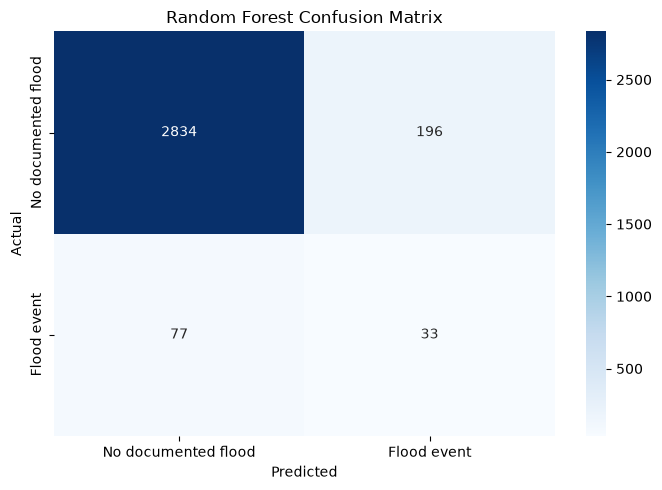

ROC-AUC score: 0.7346204620462047


,Feature,Importance
5,rainfall_7day_mm,0.278197
2,relative_humidity,0.167773
8,day_sin,0.120905
4,rainfall_3day_mm,0.112366
6,month_sin,0.106917
1,temperature_c,0.057684
9,day_cos,0.052851
0,rainfall_mm,0.045813
3,wind_speed,0.043731
7,month_cos,0.013762


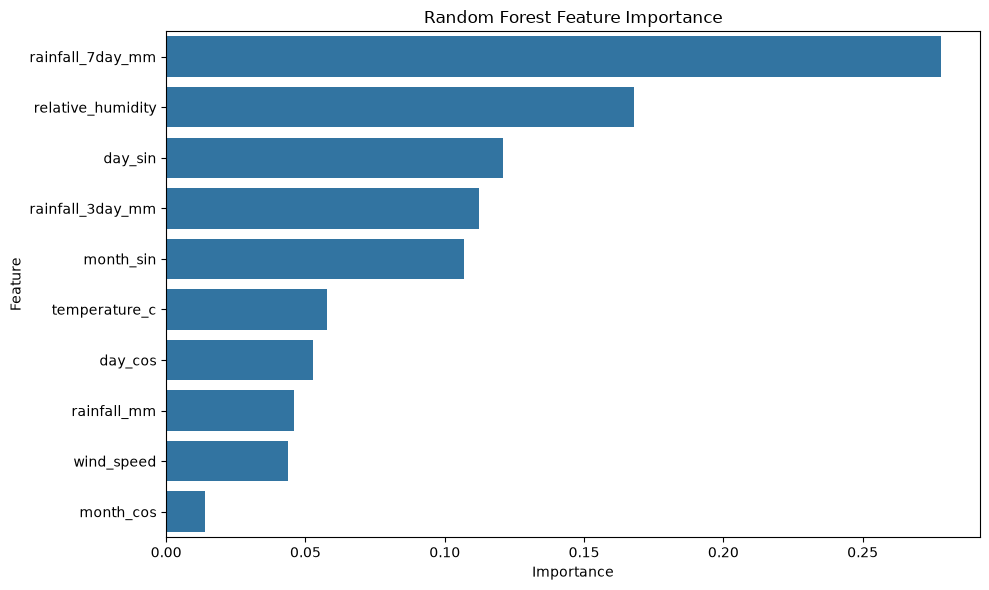

,Metric,Score
0,Accuracy,0.913057
1,Balanced Accuracy,0.617657
2,F1 Score,0.194690
3,ROC AUC,0.734620
4,Average Precision,0.105573



Model evaluation completed!


In [52]:
# ==========================================
# STEP 12: MODEL EVALUATION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_recall_curve
)

print("Evaluating trained model...")

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No documented flood", "Flood event"],
    yticklabels=["No documented flood", "Flood event"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ROC-AUC
roc_score = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC score:", roc_score)

# Feature importance
importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

# Save evaluation report
evaluation = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC AUC": roc_score,
    "Average Precision": average_precision_score(
        y_test, y_probability
    )
}

evaluation_df = pd.DataFrame(
    list(evaluation.items()),
    columns=["Metric", "Score"]
)

display(evaluation_df)

evaluation_df.to_csv(
    output_dir / "model_evaluation.csv",
    index=False
)

importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("\nModel evaluation completed!")

In [53]:
# ==========================================
# STEP 13: HYPERPARAMETER TUNING
# ==========================================

from sklearn.model_selection import (
    RandomizedSearchCV,
    TimeSeriesSplit
)

print("Starting hyperparameter tuning...")

# Check that time-series folds have both classes
cv = TimeSeriesSplit(n_splits=3)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train), start=1
):

    if (
        y_train.iloc[train_idx].nunique() != 2
        or y_train.iloc[val_idx].nunique() != 2
    ):
        raise ValueError(
            f"Time-series fold {fold} lacks both classes. "
            "More historical labeled observations are needed."
        )

param_grid = {
    "n_estimators": [200, 300, 400],
    "max_depth": [8, 12, 18, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.8],
    "class_weight": ["balanced", "balanced_subsample"]
}

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=8,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train)

best_model = search.best_estimator_

print("\nHYPERPARAMETER TUNING COMPLETED!")

print("\nBest parameters:")
print(search.best_params_)

print("\nBest cross-validation average precision:")
print(search.best_score_)

# Final evaluation on untouched test set
final_predictions = best_model.predict(X_test)

final_probabilities = (
    best_model.predict_proba(X_test)[:, 1]
)

print("\nFINAL TEST RESULTS")

print(
    classification_report(
        y_test,
        final_predictions,
        zero_division=0
    )
)

print(
    "Final accuracy:",
    accuracy_score(y_test, final_predictions)
)

print(
    "Final balanced accuracy:",
    balanced_accuracy_score(y_test, final_predictions)
)

print(
    "Final F1:",
    f1_score(y_test, final_predictions, zero_division=0)
)

print(
    "Final average precision:",
    average_precision_score(y_test, final_probabilities)
)

# Use the tuned model from now on
rf_model = best_model

print("\nTuned model selected successfully!")

Starting hyperparameter tuning...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

HYPERPARAMETER TUNING COMPLETED!

Best parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': 8, 'class_weight': 'balanced'}

Best cross-validation average precision:
0.03471442875420894

FINAL TEST RESULTS
              precision    recall  f1-score   support

           0       0.98      0.87      0.92      3030
           1       0.11      0.41      0.17       110

    accuracy                           0.86      3140
   macro avg       0.54      0.64      0.55      3140
weighted avg       0.95      0.86      0.90      3140

Final accuracy: 0.85828025477707
Final balanced accuracy: 0.6418391839183919
Final F1: 0.16822429906542055
Final average precision: 0.10061736463359723

Tuned model selected successfully!


In [54]:
# ==========================================
# STEP 14: MODEL SAVING
# ==========================================

import joblib
from datetime import datetime

print("Saving trained flood risk model...")

model_dir = PROJECT_DIR / "flood_model"
model_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": rf_model,
    "feature_columns": feature_columns,
    "model_name": "Random Forest Classifier",
    "target": "recorded_flood_event",
    "training_date": datetime.now().isoformat(),
    "data_source": "NASA POWER and Hyderabad flood inventory",
    "label_definition": (
        "1 = documented flood date; "
        "0 = date absent from the available inventory"
    )
}

model_path = model_dir / "flood_risk_model.joblib"

joblib.dump(
    model_bundle,
    model_path
)

# Verify saved model
loaded_bundle = joblib.load(model_path)

print("\nMODEL SAVED SUCCESSFULLY!")

print("Model path:", model_path)

print("Model name:", loaded_bundle["model_name"])

print("Features:", loaded_bundle["feature_columns"])

print("Training date:", loaded_bundle["training_date"])

print("\nModel saving and verification completed!")

Saving trained flood risk model...

MODEL SAVED SUCCESSFULLY!
Model path: C:\Users\DELL\flood_model\flood_risk_model.joblib
Model name: Random Forest Classifier
Features: ['rainfall_mm', 'temperature_c', 'relative_humidity', 'wind_speed', 'rainfall_3day_mm', 'rainfall_7day_mm', 'month_sin', 'month_cos', 'day_sin', 'day_cos']
Training date: 2026-11-17T19:36:28.229122

Model saving and verification completed!


In [55]:
# ==========================================
# STEP 15: FASTAPI BACKEND DEVELOPMENT
# ==========================================

from pathlib import Path

api_dir = PROJECT_DIR / "flood_api"
api_dir.mkdir(parents=True, exist_ok=True)

app_code = r'''
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel, Field

BASE_DIR = Path(__file__).resolve().parent

MODEL_PATH = (
    BASE_DIR.parent /
    "flood_model" /
    "flood_risk_model.joblib"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}"
    )

bundle = joblib.load(MODEL_PATH)

model = bundle["model"]
feature_columns = bundle["feature_columns"]

app = FastAPI(
    title="Hyderabad Flood Risk Prediction API",
    description="Machine learning based flood event classification",
    version="1.0.0"
)

# Development CORS configuration.
# Restrict origins to your actual frontend domain before production.
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=False,
    allow_methods=["*"],
    allow_headers=["*"]
)


class FloodInput(BaseModel):

    date: str

    rainfall_mm: float = Field(ge=0)
    temperature_c: float
    relative_humidity: float = Field(ge=0, le=100)
    wind_speed: float = Field(ge=0)

    rainfall_3day_mm: float = Field(ge=0)
    rainfall_7day_mm: float = Field(ge=0)


@app.get("/")
def home():

    return {
        "message": "Hyderabad Flood Risk API is running",
        "model": bundle["model_name"]
    }


@app.get("/health")
def health():

    return {
        "status": "healthy",
        "model_loaded": True
    }


@app.post("/predict")
def predict_flood(data: FloodInput):

    try:

        date_value = pd.to_datetime(
            data.date,
            errors="raise"
        )

        month = date_value.month
        day_of_year = date_value.dayofyear

        input_data = pd.DataFrame([{

            "rainfall_mm": data.rainfall_mm,

            "temperature_c": data.temperature_c,

            "relative_humidity": data.relative_humidity,

            "wind_speed": data.wind_speed,

            "rainfall_3day_mm": data.rainfall_3day_mm,

            "rainfall_7day_mm": data.rainfall_7day_mm,

            "month_sin": np.sin(
                2 * np.pi * month / 12
            ),

            "month_cos": np.cos(
                2 * np.pi * month / 12
            ),

            "day_sin": np.sin(
                2 * np.pi * day_of_year / 365.25
            ),

            "day_cos": np.cos(
                2 * np.pi * day_of_year / 365.25
            )

        }])

        input_data = input_data[feature_columns]

        prediction = int(model.predict(input_data)[0])

        probabilities = model.predict_proba(input_data)[0]

        positive_index = list(model.classes_).index(1)

        score = float(probabilities[positive_index])

        # Display bands are indicative, not official warning levels.
        if score >= 0.50:
            risk_level = "High"
        elif score >= 0.25:
            risk_level = "Moderate"
        else:
            risk_level = "Low"

        return {

            "prediction": prediction,

            "prediction_label": (
                "Flood event" if prediction == 1
                else "No documented flood event"
            ),

            "model_score_percent": round(score * 100, 2),

            "risk_level": risk_level,

            "note": (
                "Experimental model trained on historical "
                "documented flood-event labels. "
                "Not an official flood warning."
            )

        }

    except Exception as error:

        raise HTTPException(
            status_code=400,
            detail=str(error)
        )
'''

app_file = api_dir / "app.py"

app_file.write_text(
    app_code,
    encoding="utf-8"
)

print("FASTAPI BACKEND CREATED!")

print("Backend directory:", api_dir)

print("Backend file:", app_file)

print("\nAvailable endpoints:")

print("GET  /")
print("GET  /health")
print("POST /predict")

print("\nFastAPI backend code generated successfully!")

FASTAPI BACKEND CREATED!
Backend directory: C:\Users\DELL\flood_api
Backend file: C:\Users\DELL\flood_api\app.py

Available endpoints:
GET  /
GET  /health
POST /predict

FastAPI backend code generated successfully!


In [56]:
# ==========================================
# STEP 16: FRONTEND AND DEPLOYMENT PREPARATION
# ==========================================

# 1. Requirements file
requirements = """
fastapi
uvicorn
pandas
numpy
scikit-learn
joblib
pydantic
"""

(api_dir / "requirements.txt").write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

# 2. Render deployment configuration
render_config = """
services:
  - type: web
    name: hyderabad-flood-api
    runtime: python
    buildCommand: pip install -r requirements.txt
    startCommand: uvicorn app:app --host 0.0.0.0 --port $PORT
"""

(api_dir / "render.yaml").write_text(
    render_config.strip() + "\n",
    encoding="utf-8"
)

# 3. JavaScript helper for existing frontend
javascript_code = r'''
async function getFloodRisk(inputData) {

    const API_URL = "http://127.0.0.1:8000";

    try {

        const response = await fetch(
            `${API_URL}/predict`,
            {
                method: "POST",

                headers: {
                    "Content-Type": "application/json"
                },

                body: JSON.stringify(inputData)
            }
        );

        if (!response.ok) {

            const error = await response.json();

            throw new Error(
                error.detail || "Prediction failed"
            );
        }

        return await response.json();

    } catch (error) {

        console.error("Flood API error:", error);

        throw error;
    }
}
'''

js_file = api_dir / "flood_api_client.js"

js_file.write_text(
    javascript_code,
    encoding="utf-8"
)

print("FRONTEND AND DEPLOYMENT FILES CREATED")

print("\nGenerated files:")

for file in api_dir.iterdir():
    print(file.name)

print("\nFrontend integration example:")

print("""
const result = await getFloodRisk({
    date: "2023-10-01",
    rainfall_mm: 20,
    temperature_c: 26,
    relative_humidity: 80,
    wind_speed: 2,
    rainfall_3day_mm: 45,
    rainfall_7day_mm: 80
});

console.log(result);
""")

print("\nDeployment preparation completed!")

FRONTEND AND DEPLOYMENT FILES CREATED

Generated files:
app.py
flood_api_client.js
render.yaml
requirements.txt

Frontend integration example:

const result = await getFloodRisk({
    date: "2023-10-01",
    rainfall_mm: 20,
    temperature_c: 26,
    relative_humidity: 80,
    wind_speed: 2,
    rainfall_3day_mm: 45,
    rainfall_7day_mm: 80
});

console.log(result);


Deployment preparation completed!


In [57]:
# ==========================================
# STEP 17: START AND TEST FASTAPI
# ==========================================

import subprocess
import sys
import time
import requests

print("Starting Hyderabad Flood Risk API...")

# Start server
api_log = open(
    api_dir / "api_server.log",
    "w",
    encoding="utf-8"
)

api_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "app:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=str(api_dir),
    stdout=api_log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

# Check server
if api_process.poll() is not None:

    api_log.close()

    print("API server failed to start.")

    print(
        (api_dir / "api_server.log").read_text(
            encoding="utf-8",
            errors="replace"
        )
    )

    raise RuntimeError("FastAPI startup failed.")

health_response = requests.get(
    "http://127.0.0.1:8000/health",
    timeout=20
)

print("\nHEALTH CHECK:")
print(health_response.json())

# Test prediction endpoint
test_input = {
    "date": "2023-10-01",
    "rainfall_mm": 20,
    "temperature_c": 26,
    "relative_humidity": 80,
    "wind_speed": 2,
    "rainfall_3day_mm": 45,
    "rainfall_7day_mm": 80
}

prediction_response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=test_input,
    timeout=30
)

prediction_response.raise_for_status()

print("\nTEST PREDICTION:")
display(pd.DataFrame([
    prediction_response.json()
]))

print("\nFASTAPI TEST COMPLETED!")

print("\nAPI URL:")
print("http://127.0.0.1:8000")

print("\nAPI DOCUMENTATION:")
print("http://127.0.0.1:8000/docs")

Starting Hyderabad Flood Risk API...

HEALTH CHECK:
{'status': 'healthy', 'model_loaded': True}

TEST PREDICTION:


,prediction,prediction_label,model_score_percent,risk_level,note
0,0,No documented flood event,13.43,Low,Experimental model trained on historical docum...



FASTAPI TEST COMPLETED!

API URL:
http://127.0.0.1:8000

API DOCUMENTATION:
http://127.0.0.1:8000/docs


In [58]:
# ==========================================
# STEP 18: PREPARE MODEL FOR DEPLOYMENT
# ==========================================

import shutil

source_model = (
    PROJECT_DIR /
    "flood_model" /
    "flood_risk_model.joblib"
)

destination_model = (
    api_dir /
    "flood_risk_model.joblib"
)

if not source_model.exists():
    raise FileNotFoundError("Trained model is missing.")

shutil.copy2(
    source_model,
    destination_model
)

# Update backend model path
app_code = app_code.replace(
    '''BASE_DIR.parent /
    "flood_model" /
    "flood_risk_model.joblib"''',
    '''BASE_DIR /
    "flood_risk_model.joblib"'''
)

app_file.write_text(
    app_code,
    encoding="utf-8"
)

print("Deployment model copied successfully!")

print("Model:", destination_model)
print("Backend:", app_file)

print("\nBackend is ready for independent deployment.")

Deployment model copied successfully!
Model: C:\Users\DELL\flood_api\flood_risk_model.joblib
Backend: C:\Users\DELL\flood_api\app.py

Backend is ready for independent deployment.
